# When the average lies — masked growth and decline at every spatial scale

A province's economy is usually monitored with **one number**: total real-sales growth.
This notebook shows, case by case and map by map, how that number can be an artifact of a
*single parish* — a mine ramping up, a border town collapsing — while the rest of the
province quietly does the opposite. And it shows how the **Price decomposition**
(selection + transmission) turns the anonymous average into a flag that tells you *where
to look*.

**What happens here, in order:**

1. **STEP B — the detector.** For every province × annual step we compute three answers to
   "how did it grow?": the aggregate (the dashboard number), the same aggregate *without
   its biggest single mover* (leave-one-out), and the median parish. When the first is
   healthy and the other two are not (or vice-versa), the average is masking something.
2. **STEP C — rank the flags.** The masking gap |aggregate − leave-one-out| ranks the
   flagged cases; the top `N_CASES` get the full visual treatment.
3. **FIG 0** — every province-year on one scatter: the dashboard vs the leave-one-out.
4. **STEP D — the Price machinery.** One function that computes, at any scale (province /
   canton / parish) and inside any province, each unit's own growth, its **selection**
   contribution (did firm formation favour high- or low-sales units?) and its
   **transmission** contribution (firm-weighted own growth of incumbent units).
5. **STEP E — the panels.** For each case, a 3×3 figure: rows go **coarse → fine**
   (Ecuador at province scale → the flagged province at canton scale → at parish scale),
   columns go **average → decomposition** (own growth | selection | transmission). The
   first map is what a macro dashboard sees; the last row is what actually happened.

Data: the deflated SRI panel (`load_real_panel`, constant-2025 USD). Conventions shared
with the other notebooks: parish codes are 6-digit strings (province = first 2, canton =
first 4); 2024 is missing November, so every 2023↔2024 comparison uses the same 11 months
of both years; Galápagos exists in the data but not in the shapefile (it renders grey).

In [1]:
# ==============================================================================
# STEP A -- setup: engine, panel, names, shapefiles, parameters
# ------------------------------------------------------------------------------
# Everything tunable lives here: the annual steps to scan, how many cases get
# the full panel treatment, the flag thresholds, the colour cap.
# ==============================================================================
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# The project root is the folder that holds ecuador_price/ (this notebook lives in notebooks/).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "ecuador_price").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
from ecuador_price import decomposition as dec, paths, style
style.apply()                      # the project's fonts and colours

OUT_DIR = paths.STORY / "masked_multiscale"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- parameters (timeframe and every rule live here) -------------------------
STEPS        = [(y, y + 1) for y in range(2017, 2024)]  # 2017→18 ... 2023→24
N_CASES      = 10       # flagged cases that get the full multiscale panel
MIN_PARISHES = 3        # a province needs >= this many surviving parishes
AGG_MIN      = 0.02     # |aggregate growth| must exceed this to be maskable
WO_FLAT      = 0.005    # leave-one-out within +/- this = "the rest went nowhere"
CARRY_FRAC   = 0.7      # ...or one parish carries > this share of the growth
Q_CAP        = 0.98     # symmetric colour cap: this quantile of |values|

# palette (project conventions)
TRANS_RED, SEL_BLUE = style.RED, style.BLUE
PURPLE, ORANGE, GRAY = style.PURPLE, style.ORANGE, "0.45"

panel = dec.load_real_panel()                     # anio, mes, cod_parr, real_sales, total_firms
panel["m"] = panel["mes"].astype(int)
MONTHS_2324 = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12]  # months present in BOTH 2023 & 2024

# names: dpa.xlsx (has Galápagos); col 1 = parish code, 3 = province, 5 = canton, 7 = parish
dpa = pd.read_excel(paths.DPA_XLSX, dtype=str, header=None)
dpa = dpa[dpa[1].astype(str).str.match(r"^\d{6}$", na=False)]
PNAME = {c: f"{p.title().strip()} ({k.title().strip()})" for c, k, p in zip(dpa[1], dpa[5], dpa[7])}
CNAME = {c[:4]: k.title().strip() for c, k in zip(dpa[1], dpa[5])}
PROV  = {c[:2]: pr.title().strip() for c, pr in zip(dpa[1], dpa[3])}

# shapefiles: one GeoDataFrame per level; codes are strings on both sides, so a
# decomposition table merges with a plain string join (Galápagos absent -> grey)
GEO = {
    "province": gpd.read_file(paths.SHAPEFILES["province"])[["DPA_PROVIN", "geometry"]],
    "canton":   gpd.read_file(paths.SHAPEFILES["canton"])[["DPA_CANTON", "geometry"]],
    "parish":   gpd.read_file(paths.SHAPEFILES["parish"])[["DPA_PARROQ", "geometry"]],
}


def parish_sales(y0, y1):
    '''Wide parish x {y0,y1} real-sales table over parishes valid (> $1k) in BOTH
    years. Any comparison touching 2024 uses the 11 months shared with 2023.'''
    d = panel[panel["year"].isin([y0, y1])]
    if 2024 in (y0, y1):
        d = d[d["m"].isin(MONTHS_2324)]
    w = d.groupby(["cod_parr", "year"])["real_sales"].sum().unstack().dropna()
    return w[(w > dec.SALES_FLOOR).all(axis=1)]


print(f"panel {panel.year.min()}-{panel.year.max()};  steps {STEPS[0][0]}→{STEPS[-1][1]};  "
      "shapefile units: " + ", ".join(f"{k} {len(g)}" for k, g in GEO.items()))
print(f"figures -> {OUT_DIR}")

panel 2017-2025;  steps 2017→2024;  shapefile units: province 29, canton 224, parish 1036
figures -> results/story/masked_multiscale


## STEP B — the detector: three answers to "how did province X do?"

For every province and every annual step we ask the same question three ways:

- **`G_agg`** — the aggregate real-sales growth of the province's surviving parishes.
  This is the number a dashboard, a ministry slide, or a naive GDP-style average reports.
- **`G_wo`** — the *same* aggregate after removing the one parish with the biggest dollar
  change (leave-one-out). If the number survives, the growth is broad; if it flips, one
  parish *was* the number.
- **`med`** — the median parish's growth: one-parish-one-vote, immune to any single giant.

**Masked growth**: the aggregate is up more than +2 % but the leave-one-out is flat/negative,
or one parish carries more than 70 % of it. **Masked decline** is the mirror: the aggregate
is down more than −2 % but the rest of the province was actually fine. Thresholds are the
`AGG_MIN` / `WO_FLAT` / `CARRY_FRAC` parameters — same rule as the story notebook, rebuilt
here so this notebook stands alone.

In [2]:
# ==============================================================================
# STEP B -- scan every province x annual step, flag the masked cases
# ==============================================================================
rows = []
for y0, y1 in STEPS:
    w = parish_sales(y0, y1)
    for code_, grp in w.groupby(w.index.str[:2]):
        if len(grp) < MIN_PARISHES:
            continue
        g   = np.log(grp[y1] / grp[y0])                     # per-parish growth
        G   = np.log(grp[y1].sum() / grp[y0].sum())         # the dashboard number
        top = (grp[y1] - grp[y0]).abs().idxmax()            # biggest dollar mover
        wo  = grp.drop(top)
        rows.append(dict(prov_code=code_, prov=PROV.get(code_, code_),
                         y0=y0, y1=y1, step=f"{y0}→{str(y1)[2:]}", n=len(grp),
                         G_agg=G, G_wo=np.log(wo[y1].sum() / wo[y0].sum()),
                         med=g.median(), n_shrink=int((g < 0).sum()),
                         top_code=top, top=PNAME.get(top, top),
                         top_dshare=(grp.loc[top, y1] - grp.loc[top, y0])
                                    / (grp[y1].sum() - grp[y0].sum())))
scan = pd.DataFrame(rows)

m_grow = scan[(scan.G_agg >  AGG_MIN) & ((scan.G_wo <  WO_FLAT) |
              (scan.G_agg - scan.G_wo > CARRY_FRAC * scan.G_agg))].assign(kind="masked growth")
m_decl = scan[(scan.G_agg < -AGG_MIN) &  (scan.G_wo > -WO_FLAT)].assign(kind="masked decline")
flagged = pd.concat([m_grow, m_decl])
scan.to_csv(OUT_DIR / "masked_growth_scan.csv", index=False)

pct = lambda s: (np.expm1(s) * 100).round(1)
show = flagged.assign(G_agg=pct(flagged.G_agg), G_wo=pct(flagged.G_wo),
                      med=pct(flagged.med), top_dshare=(flagged.top_dshare * 100).round(0))
cols = ["kind", "prov", "step", "n", "G_agg", "G_wo", "med", "n_shrink", "top", "top_dshare"]
print(f"{len(m_grow)} masked-growth + {len(m_decl)} masked-decline flags "
      f"out of {len(scan)} province-years  (G_agg/G_wo/med in %)\n")
print(show.sort_values(["kind", "G_agg"], ascending=[True, False])[cols].to_string(index=False))

9 masked-growth + 10 masked-decline flags out of 168 province-years  (G_agg/G_wo/med in %)

          kind                           prov    step  n  G_agg  G_wo   med  n_shrink                                            top  top_dshare
masked decline                    Santa Elena 2023→24 11   -2.7   0.0   2.7         4                          Chanduy (Santa Elena)       101.0
masked decline                          Azuay 2022→23 74   -3.0   0.9   7.2        28                               Sayausi (Cuenca)       128.0
masked decline                          Cañar 2019→20 30   -3.3   2.6  -2.0        17                        La Troncal (La Troncal)       145.0
masked decline                           Napo 2023→24 23   -4.0   3.2  -8.3        14                                    Tena (Tena)       149.0
masked decline                     Tungurahua 2023→24 50   -5.3   0.8  -1.2        26                                Ambato (Ambato)       107.0
masked decline                     Esm

## STEP C — which cases matter most?

The **masking gap** `|G_agg − G_wo|` measures how far the dashboard number moves when a
single parish is removed — it is literally "how much of the average was one place". We
rank the flagged cases by that gap and keep the top `N_CASES`, making sure at least one
masked-**decline** case is featured: they are rarer but just as costly (a province written
off as collapsing when in fact one entrepôt fell and everyone else held).

One practical filter: a featured case must be *mappable*. Galápagos gets flagged in
2020→21 (Puerto Ayora's tourism rebound) but the INEC shapefile does not cover it, so it
stays in the scan and the scatter while the panels go to the next case in rank.

In [3]:
# ==============================================================================
# STEP C -- rank the flags by the masking gap, keep the top N_CASES
# ==============================================================================
flagged["gap"] = (flagged.G_agg - flagged.G_wo).abs()
ranked = flagged.sort_values("gap", ascending=False)
mappable = ranked["prov_code"].isin(GEO["province"]["DPA_PROVIN"])
if (~mappable).any():
    print("flagged but absent from the shapefile (kept in scan + scatter only): "
          + ", ".join(f"{r['prov']} {r['step']}" for _, r in ranked[~mappable].iterrows())
          + "\n")
ranked = ranked[mappable].reset_index(drop=True)
CASES = ranked.head(N_CASES)
for kind in ["masked growth", "masked decline"]:            # both kinds represented
    if not (CASES["kind"] == kind).any():
        CASES = pd.concat([CASES.head(N_CASES - 1),
                           ranked[ranked["kind"] == kind].head(1)])
CASES = CASES.reset_index(drop=True)

print("the cases that get the full multiscale treatment:\n")
for i, r in CASES.iterrows():
    print(f"{i + 1}. {r['prov']} {r['step']} — {r['kind']}: the dashboard says "
          f"{np.expm1(r.G_agg) * 100:+.1f}%, but without {r['top']} it is "
          f"{np.expm1(r.G_wo) * 100:+.1f}%  (that one parish = {r.top_dshare:+.0%} of the "
          f"change; median parish {np.expm1(r.med) * 100:+.1f}%; "
          f"{r.n_shrink}/{r.n} parishes shrank)")

flagged but absent from the shapefile (kept in scan + scatter only): Galapagos 2020→21

the cases that get the full multiscale treatment:

1. Bolivar 2023→24 — masked growth: the dashboard says +38.7%, but without Guaranda (Guaranda) it is -6.5%  (that one parish = +108% of the change; median parish +6.0%; 11/23 parishes shrank)
2. Santo Domingo De Los Tsachilas 2020→21 — masked growth: the dashboard says +25.4%, but without Santo Domingo De Los Colorados (Santo Domingo) it is -6.7%  (that one parish = +104% of the change; median parish +12.3%; 3/12 parishes shrank)
3. Zamora Chinchipe 2018→19 — masked growth: the dashboard says +20.8%, but without Los Encuentros (Yantzaza (Yanzatza)) it is -8.4%  (that one parish = +136% of the change; median parish +25.7%; 8/24 parishes shrank)
4. Carchi 2019→20 — masked decline: the dashboard says -14.2%, but without Tulcan (Tulcan) it is +3.3%  (that one parish = +107% of the change; median parish -13.5%; 21/31 parishes shrank)
5. Santo Domingo De 

## FIG 0 — the dashboard vs the leave-one-out

Every province × year is one dot. On the diagonal, the average is honest: removing the
biggest mover changes nothing. The farther a dot sits **below** the diagonal, the more its
"growth" was one parish (southeast wedge = masked growth); **above** the diagonal in the
northwest wedge = masked decline. Red dots are flagged; the numbered ones are the featured
cases dissected below.

saved -> results/story/masked_multiscale/fig0_dashboard_vs_leave_one_out.png


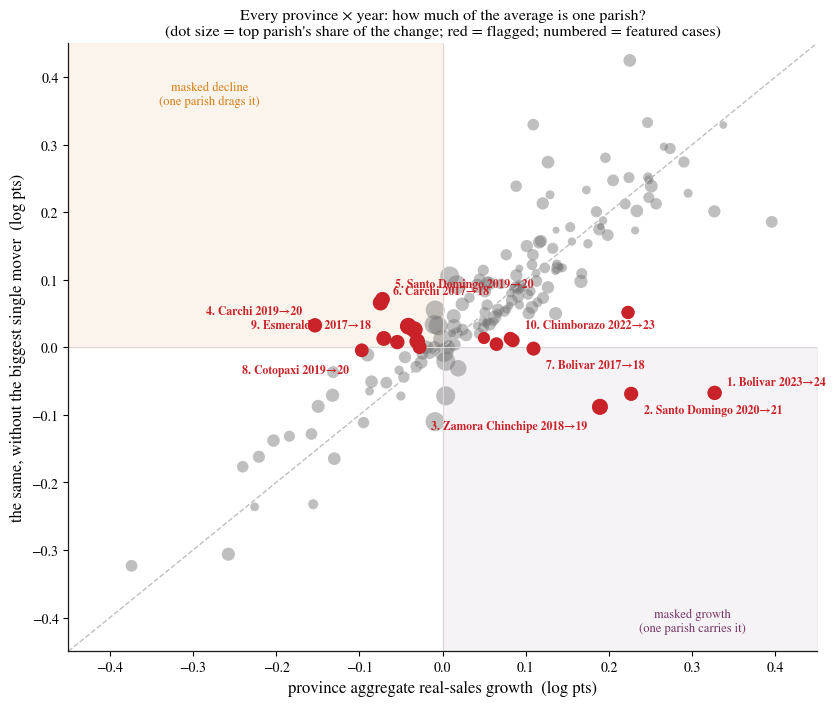

In [4]:
# ==============================================================================
# FIG 0 -- every province-year: aggregate growth vs leave-one-out growth
# ==============================================================================
fig, ax = plt.subplots(figsize=(8.6, 7.2))
lim = (-0.45, 0.45)
ax.fill_between([0, lim[1]], lim[0], 0, color=PURPLE, alpha=0.06)
ax.fill_between([lim[0], 0], 0, lim[1], color=ORANGE, alpha=0.08)
ax.plot(lim, lim, color="0.75", lw=1.0, ls="--")
ax.axhline(0, color="0.85", lw=0.8); ax.axvline(0, color="0.85", lw=0.8)
ax.scatter(scan.G_agg, scan.G_wo, s=8 + 90 * scan.top_dshare.abs().clip(0, 2),
           alpha=0.45, color=GRAY, lw=0)
ax.scatter(flagged.G_agg, flagged.G_wo, s=10 + 90 * flagged.top_dshare.abs().clip(0, 2),
           color=TRANS_RED, lw=0, zorder=5)
OFFS = [(9, 6), (9, -14), (-9, -16), (-9, 8), (9, 9)]    # hand-staggered labels
for i, r in CASES.iterrows():
    dx, dy = OFFS[i % len(OFFS)]
    ax.annotate(f"{i + 1}. {r['prov'].replace(' De Los Tsachilas', '')} {r['step']}",
                (r.G_agg, r.G_wo), textcoords="offset points", xytext=(dx, dy),
                ha="left" if dx > 0 else "right",
                fontsize=8.5, color=style.RED, fontweight="bold")
ax.text(0.30, -0.42, "masked growth\n(one parish carries it)",
        fontsize=9, color=PURPLE, ha="center")
ax.text(-0.28, 0.36, "masked decline\n(one parish drags it)",
        fontsize=9, color=style.ORANGE, ha="center")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("province aggregate real-sales growth  (log pts)")
ax.set_ylabel("the same, without the biggest single mover  (log pts)")
ax.set_title("Every province × year: how much of the average is one parish?\n"
             "(dot size = top parish's share of the change; red = flagged; "
             "numbered = featured cases)", fontsize=11.5)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig0_dashboard_vs_leave_one_out.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "fig0_dashboard_vs_leave_one_out.pdf", bbox_inches="tight")
print("saved ->", OUT_DIR / "fig0_dashboard_vs_leave_one_out.png")
plt.show()

## STEP D — the Price terms, at any scale, inside any province

One function serves every panel row. A *unit* is the first `width` digits of the parish
code (2 = province, 4 = canton, 6 = parish); passing `within=` restricts everything to one
province, so selection and transmission then decompose **that province's own**
firm-weighted mean-trait change over its cantons or parishes.

Population-path conventions, identical to the decomposition engine: firms are the
population (summed across CIIU sections within a unit-month, monthly stocks averaged over
the year), `z = ln(real annual sales)` is the trait, firm growth `w = n₁/n₀` is fitness.
With `p` the initial firm share and `q = p·w/W̄` the final one,

- **selection** `sel_c = p · (w/W̄ − 1) · (z₀ − z̄₀)` — positive when firm formation favours
  units that already had high sales (concentration), negative when it favours low-sales
  units (catch-up);
- **transmission** `trans_c = q · (z₁ − z₀)` — the incumbent unit's own growth, weighted by
  the firms that end up there (one-firm-one-vote, which is exactly why an enclave with a
  handful of giant firms *cannot* dominate it the way it dominates a dollar sum);
- **identity** (asserted on every call): `Σ sel_c + Σ trans_c = Δz̄`, the change in the
  firm-weighted mean trait.

In [5]:
# ==============================================================================
# STEP D -- per-unit growth + Price terms at any scale, inside any province
# ==============================================================================
def unit_price_table(y0, y1, width, within=None):
    '''One row per unit (= first `width` digits of cod_parr): own growth,
    selection and transmission contributions, pop path. `within` restricts the
    decomposition to the units of one province.'''
    d = panel[panel["year"].isin([y0, y1])]
    if 2024 in (y0, y1):
        d = d[d["m"].isin(MONTHS_2324)]
    d = d.assign(unit=d["cod_parr"].str[:width])
    if within is not None:
        d = d[d["unit"].str.startswith(within)]
    sales = d.groupby(["unit", "year"])["real_sales"].sum().unstack()
    firms = (d.groupby(["unit", "year", "m"])["total_firms"].sum()   # sections summed
               .groupby(["unit", "year"]).mean().unstack())          # monthly stocks -> mean
    ok = (sales > dec.SALES_FLOOR).all(axis=1) & (firms > 0).all(axis=1)
    surv = sales.index[ok]                                # valid in BOTH years
    n0, n1 = firms.loc[surv, y0], firms.loc[surv, y1]
    z0, z1 = np.log(sales.loc[surv, y0]), np.log(sales.loc[surv, y1])
    p, q = n0 / n0.sum(), n1 / n1.sum()
    w = n1 / n0
    W, Z0 = (p * w).sum(), (p * z0).sum()
    t = pd.DataFrame({"growth":  z1 - z0,                        # the average's view
                      "sel_c":   p * (w / W - 1) * (z0 - Z0),    # selection
                      "trans_c": q * (z1 - z0)})                 # transmission
    dzbar = (q * z1).sum() - Z0
    assert abs(t.sel_c.sum() + t.trans_c.sum() - dzbar) < 1e-9, "Price identity broken"
    return t


print("identity check S + T = Δz̄ at every scale of every featured case:")
for _, r in CASES.iterrows():
    for width, lev in [(2, "province"), (4, "canton"), (6, "parish")]:
        t = unit_price_table(r.y0, r.y1, width, None if width == 2 else r.prov_code)
        print(f"  {r['prov']:<30s} {r['step']} @ {lev:8s}: {len(t):4d} units   "
              f"S {t.sel_c.sum():+.4f}  T {t.trans_c.sum():+.4f}  "
              f"Δz̄ {t.sel_c.sum() + t.trans_c.sum():+.4f}")

identity check S + T = Δz̄ at every scale of every featured case:
  Bolivar                        2023→24 @ province:   24 units   S +0.0089  T +0.0088  Δz̄ +0.0177
  Bolivar                        2023→24 @ canton  :    7 units   S +0.0069  T +0.1751  Δz̄ +0.1820
  Bolivar                        2023→24 @ parish  :   23 units   S -0.0186  T +0.2244  Δz̄ +0.2058
  Santo Domingo De Los Tsachilas 2020→21 @ province:   24 units   S -0.0176  T +0.2082  Δz̄ +0.1906
  Santo Domingo De Los Tsachilas 2020→21 @ canton  :    2 units   S +0.0037  T +0.2256  Δz̄ +0.2293
  Santo Domingo De Los Tsachilas 2020→21 @ parish  :   12 units   S +0.0100  T +0.2561  Δz̄ +0.2661
  Zamora Chinchipe               2018→19 @ province:   24 units   S -0.0396  T +0.0137  Δz̄ -0.0259
  Zamora Chinchipe               2018→19 @ canton  :    9 units   S +0.0105  T +0.3555  Δz̄ +0.3660
  Zamora Chinchipe               2018→19 @ parish  :   24 units   S -0.0407  T +0.2921  Δz̄ +0.2513
  Carchi                         2

  Bolivar                        2017→18 @ province:   24 units   S -0.0247  T +0.0609  Δz̄ +0.0362
  Bolivar                        2017→18 @ canton  :    7 units   S -0.0066  T +0.1115  Δz̄ +0.1049
  Bolivar                        2017→18 @ parish  :   18 units   S -0.0661  T +0.1558  Δz̄ +0.0897
  Cotopaxi                       2019→20 @ province:   24 units   S +0.0121  T -0.1310  Δz̄ -0.1189


  Cotopaxi                       2019→20 @ canton  :    7 units   S -0.0134  T -0.0992  Δz̄ -0.1126
  Cotopaxi                       2019→20 @ parish  :   34 units   S +0.0353  T -0.1571  Δz̄ -0.1218
  Esmeraldas                     2017→18 @ province:   24 units   S -0.0247  T +0.0609  Δz̄ +0.0362
  Esmeraldas                     2017→18 @ canton  :    7 units   S -0.0476  T -0.1263  Δz̄ -0.1738
  Esmeraldas                     2017→18 @ parish  :   39 units   S -0.0393  T +0.0513  Δz̄ +0.0121
  Chimborazo                     2022→23 @ province:   24 units   S -0.0123  T +0.0317  Δz̄ +0.0194
  Chimborazo                     2022→23 @ canton  :   10 units   S +0.0460  T +0.1051  Δz̄ +0.1511
  Chimborazo                     2022→23 @ parish  :   34 units   S +0.0854  T +0.1585  Δz̄ +0.2439


## STEP E — the multiscale panels: what the average hid, scale by scale

One figure per case, always the same grammar so the eye learns to read it:

|            | col 1: **the average's view**   | col 2: **selection**            | col 3: **transmission**          |
|------------|---------------------------------|----------------------------------|----------------------------------|
| row 1      | Ecuador, province scale         | province contributions to national S | province contributions to national T |
| row 2      | flagged province, canton scale  | within-province decomposition    | within-province decomposition    |
| row 3      | flagged province, parish scale  | within-province decomposition    | within-province decomposition    |

Reading it: **row 1, column 1** is the macro dashboard — the flagged province usually
looks unremarkable, or misleadingly good/bad. Columns 2–3 are the decomposition's early
warning: when a unit's selection and transmission tell different stories (or one cell
glows in an otherwise pale map), something non-average is going on there. Rows 2–3 zoom
in and re-run the decomposition *inside* the province until the culprit is a single named
parish, outlined in black.

Diverging `RdBu_r` colours are symmetric about zero (white = nothing happening), capped at
the `Q_CAP` quantile of |values| so one outlier can't wash out the map; grey = no valid
data (below the $1k floor, or Galápagos, which the shapefile lacks).

saved -> results/story/masked_multiscale/case1_02_2023_2024.png


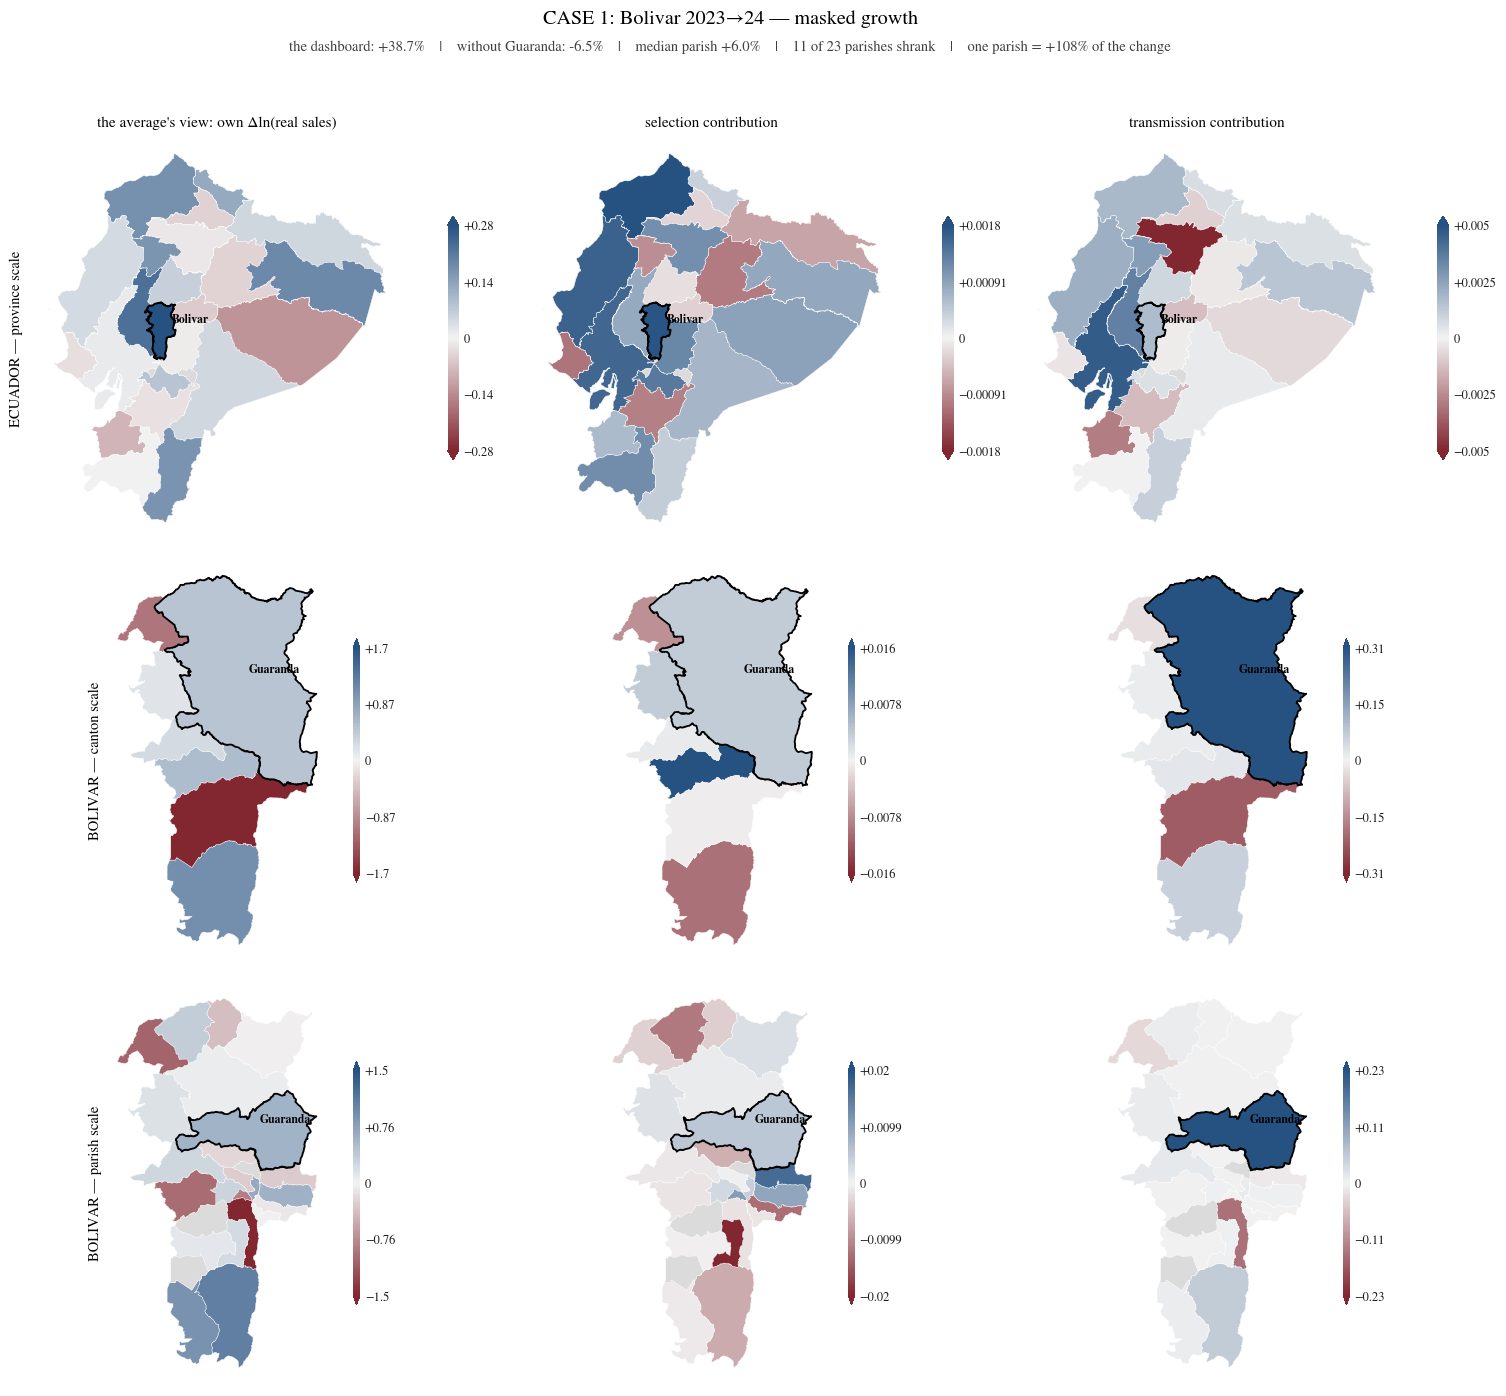

   within-Bolivar Price (2023→24):  Δz̄ +0.2058  =  S -0.0186  +  T +0.2244    |    Guaranda: sel_c +0.0054, trans_c +0.2936, own growth +0.59 log pts



saved -> results/story/masked_multiscale/case2_23_2020_2021.png


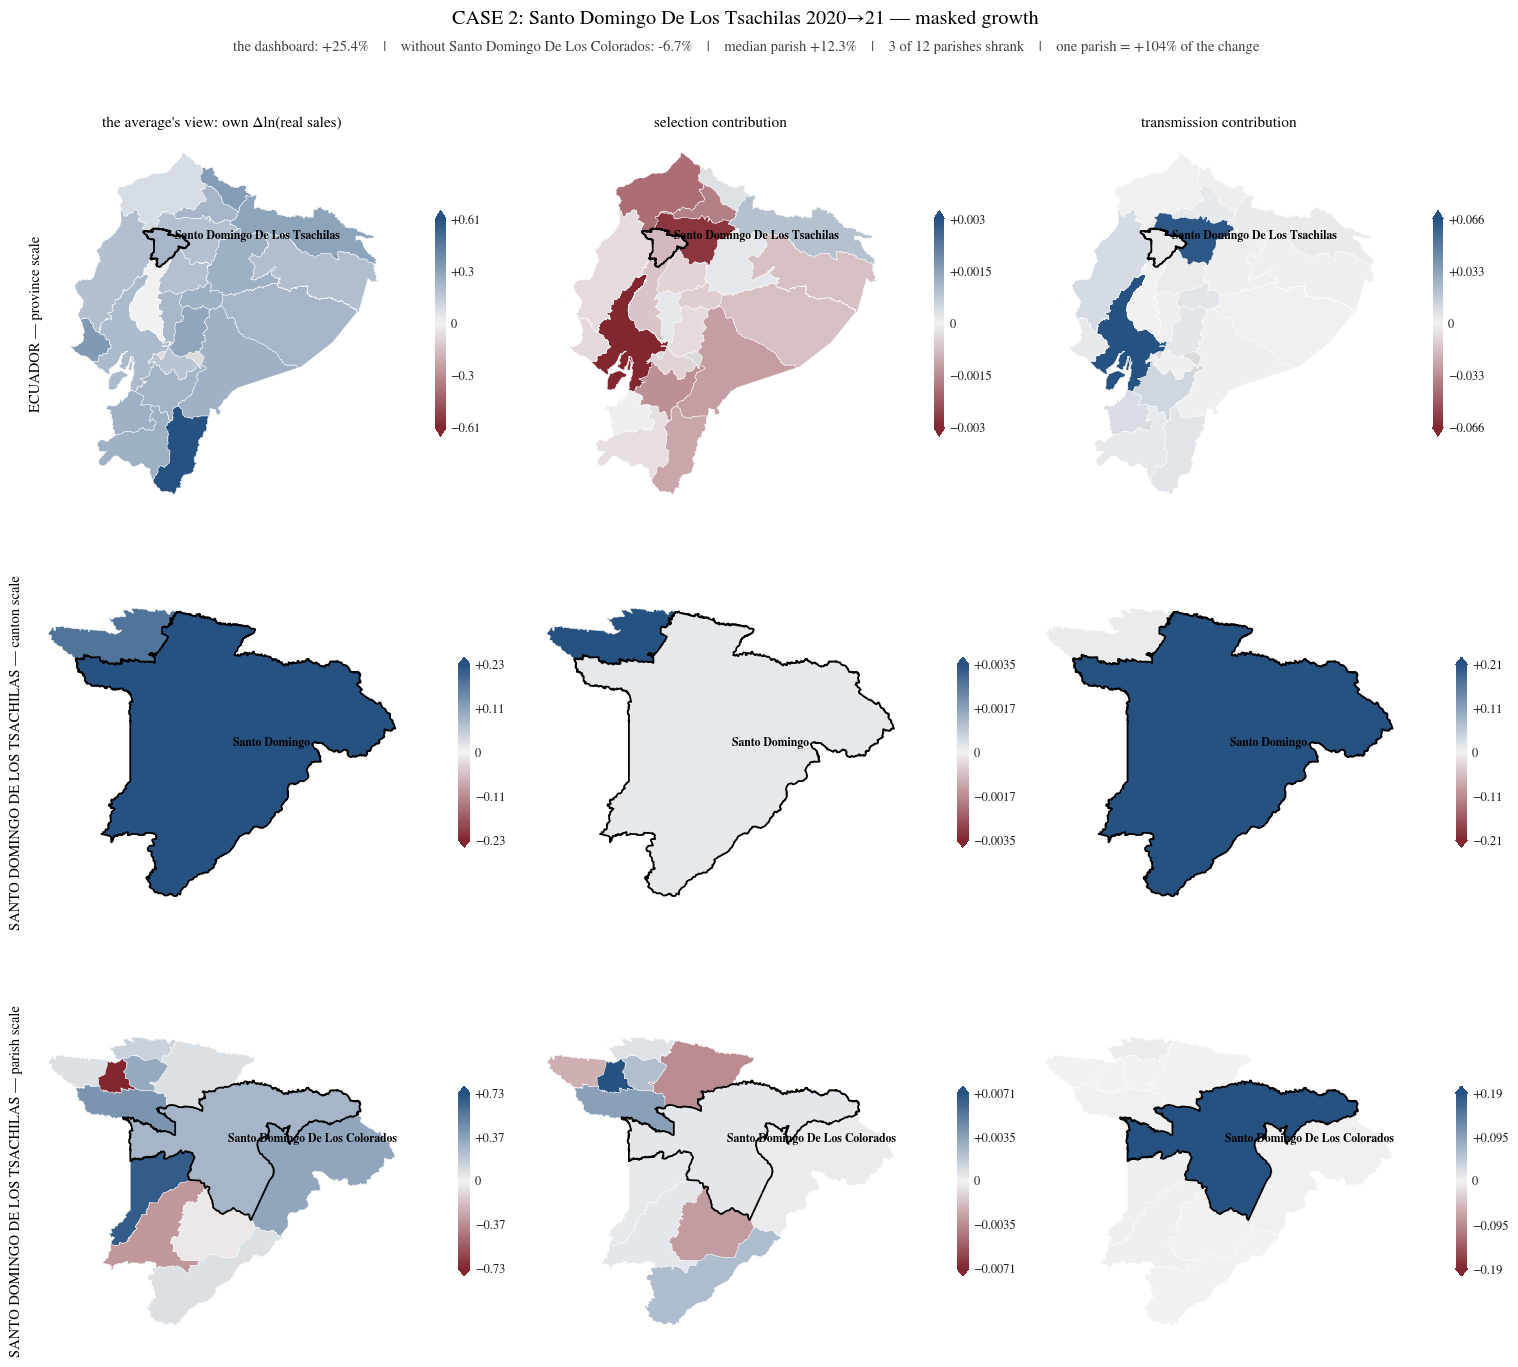

   within-Santo Domingo De Los Tsachilas Price (2020→21):  Δz̄ +0.2661  =  S +0.0100  +  T +0.2561    |    Santo Domingo De Los Colorados: sel_c +0.0005, trans_c +0.2417, own growth +0.27 log pts



saved -> results/story/masked_multiscale/case3_19_2018_2019.png


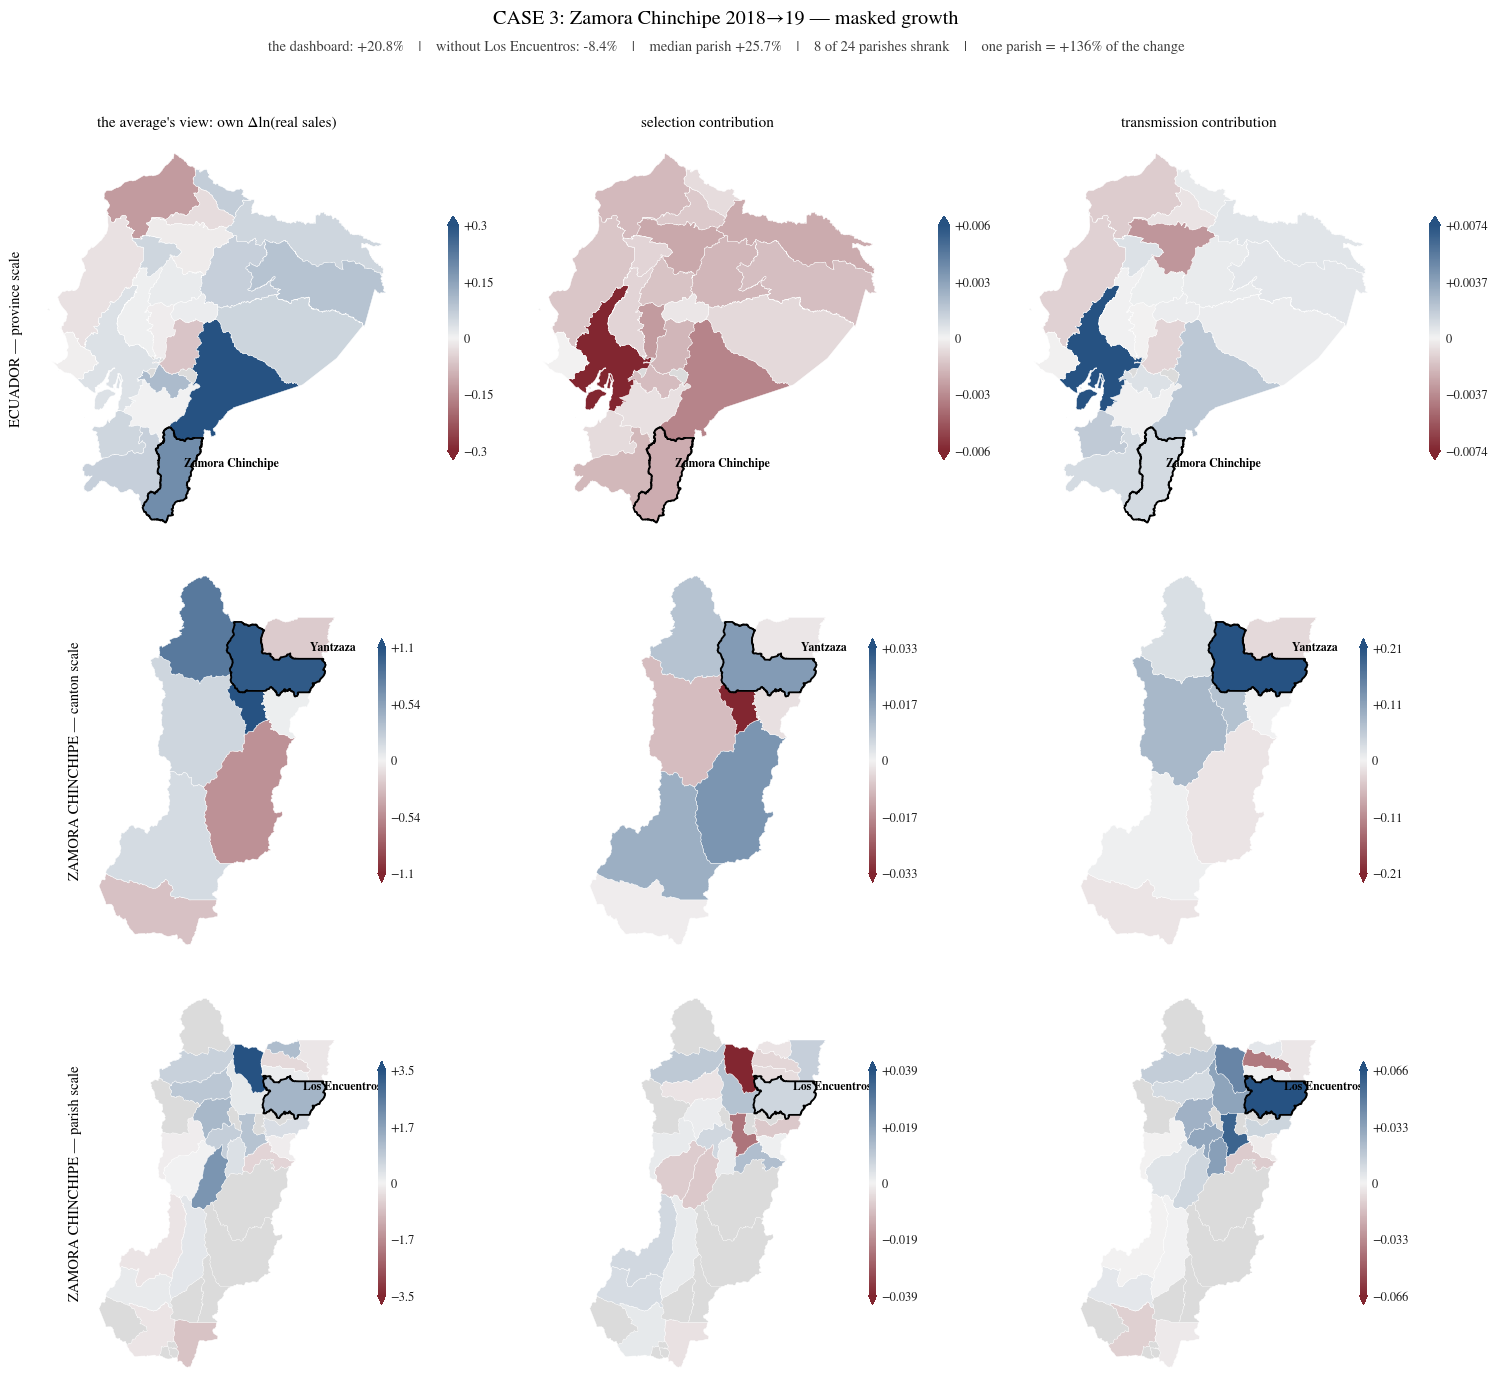

   within-Zamora Chinchipe Price (2018→19):  Δz̄ +0.2513  =  S -0.0407  +  T +0.2921    |    Los Encuentros: sel_c +0.0068, trans_c +0.0718, own growth +1.31 log pts



saved -> results/story/masked_multiscale/case4_04_2019_2020.png


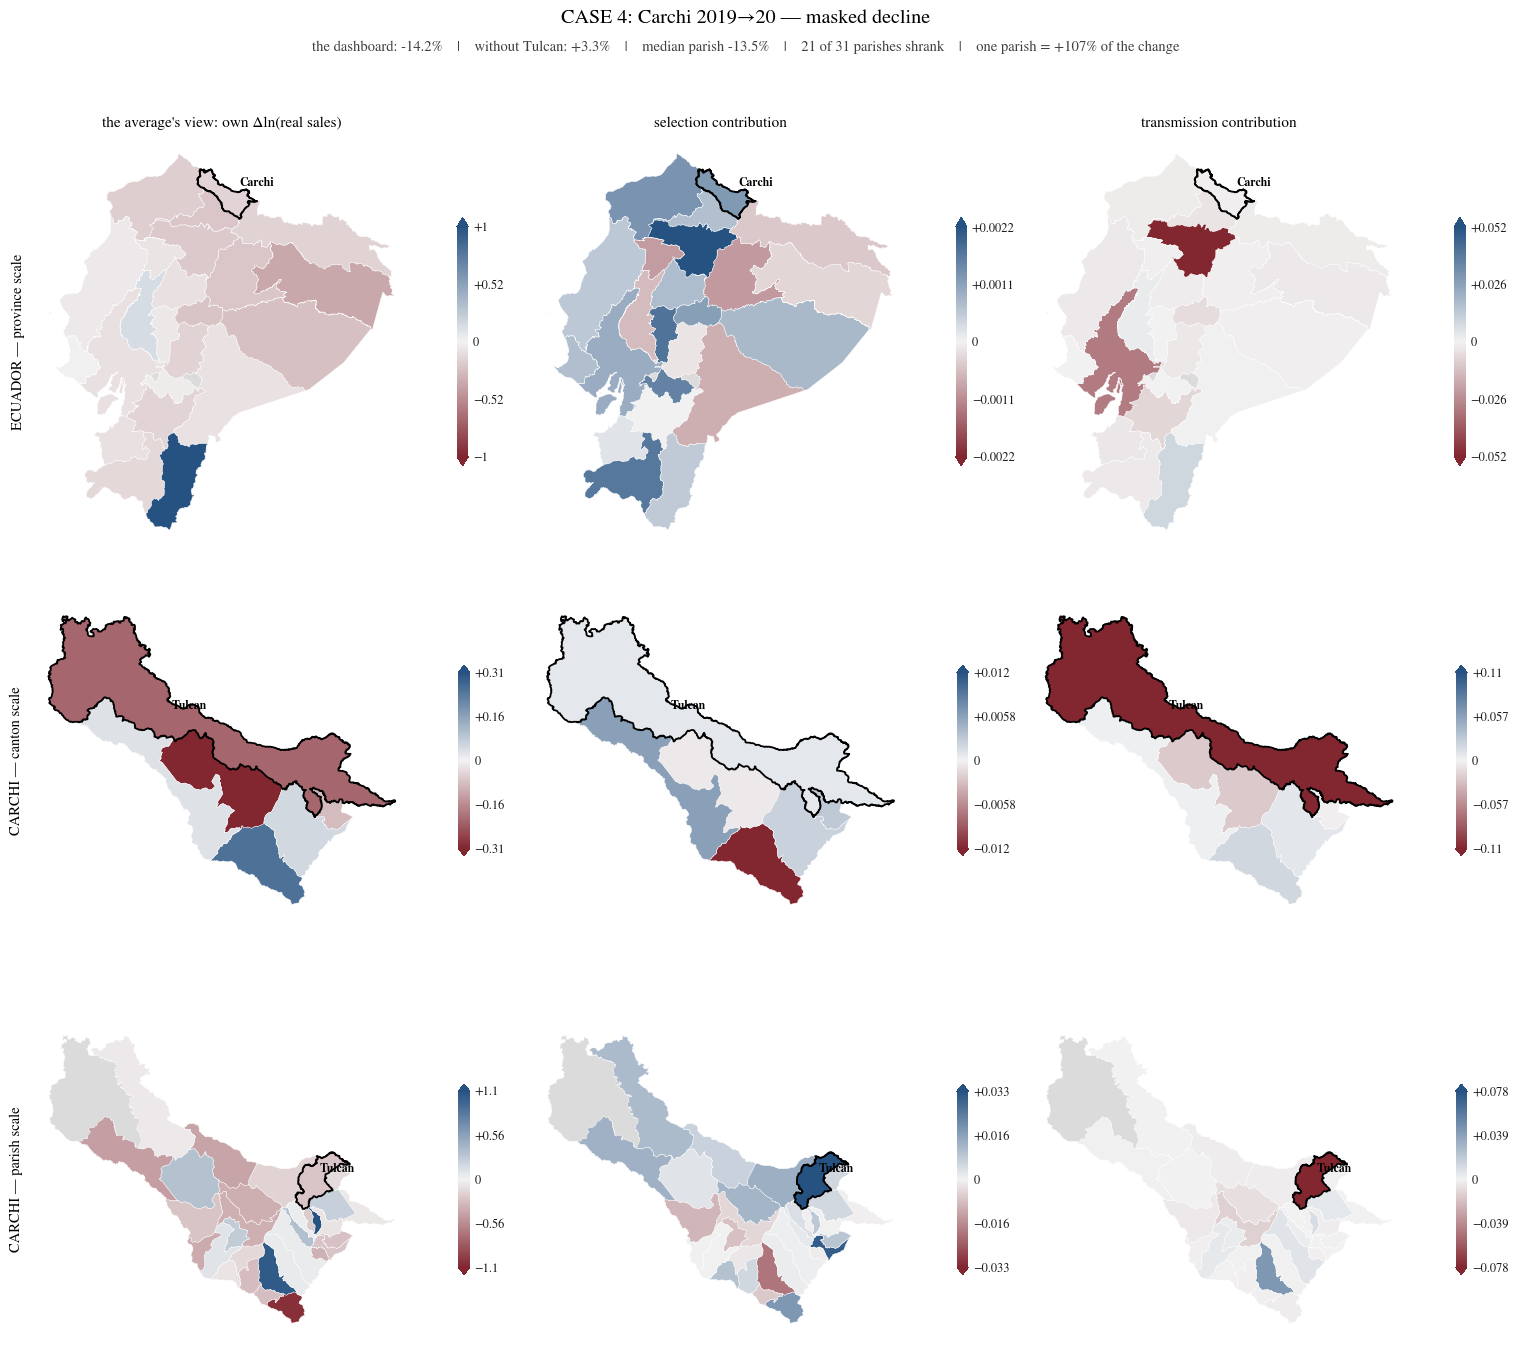

   within-Carchi Price (2019→20):  Δz̄ +0.0498  =  S +0.1445  +  T -0.0947    |    Tulcan: sel_c +0.0361, trans_c -0.1285, own growth -0.25 log pts



saved -> results/story/masked_multiscale/case5_23_2019_2020.png


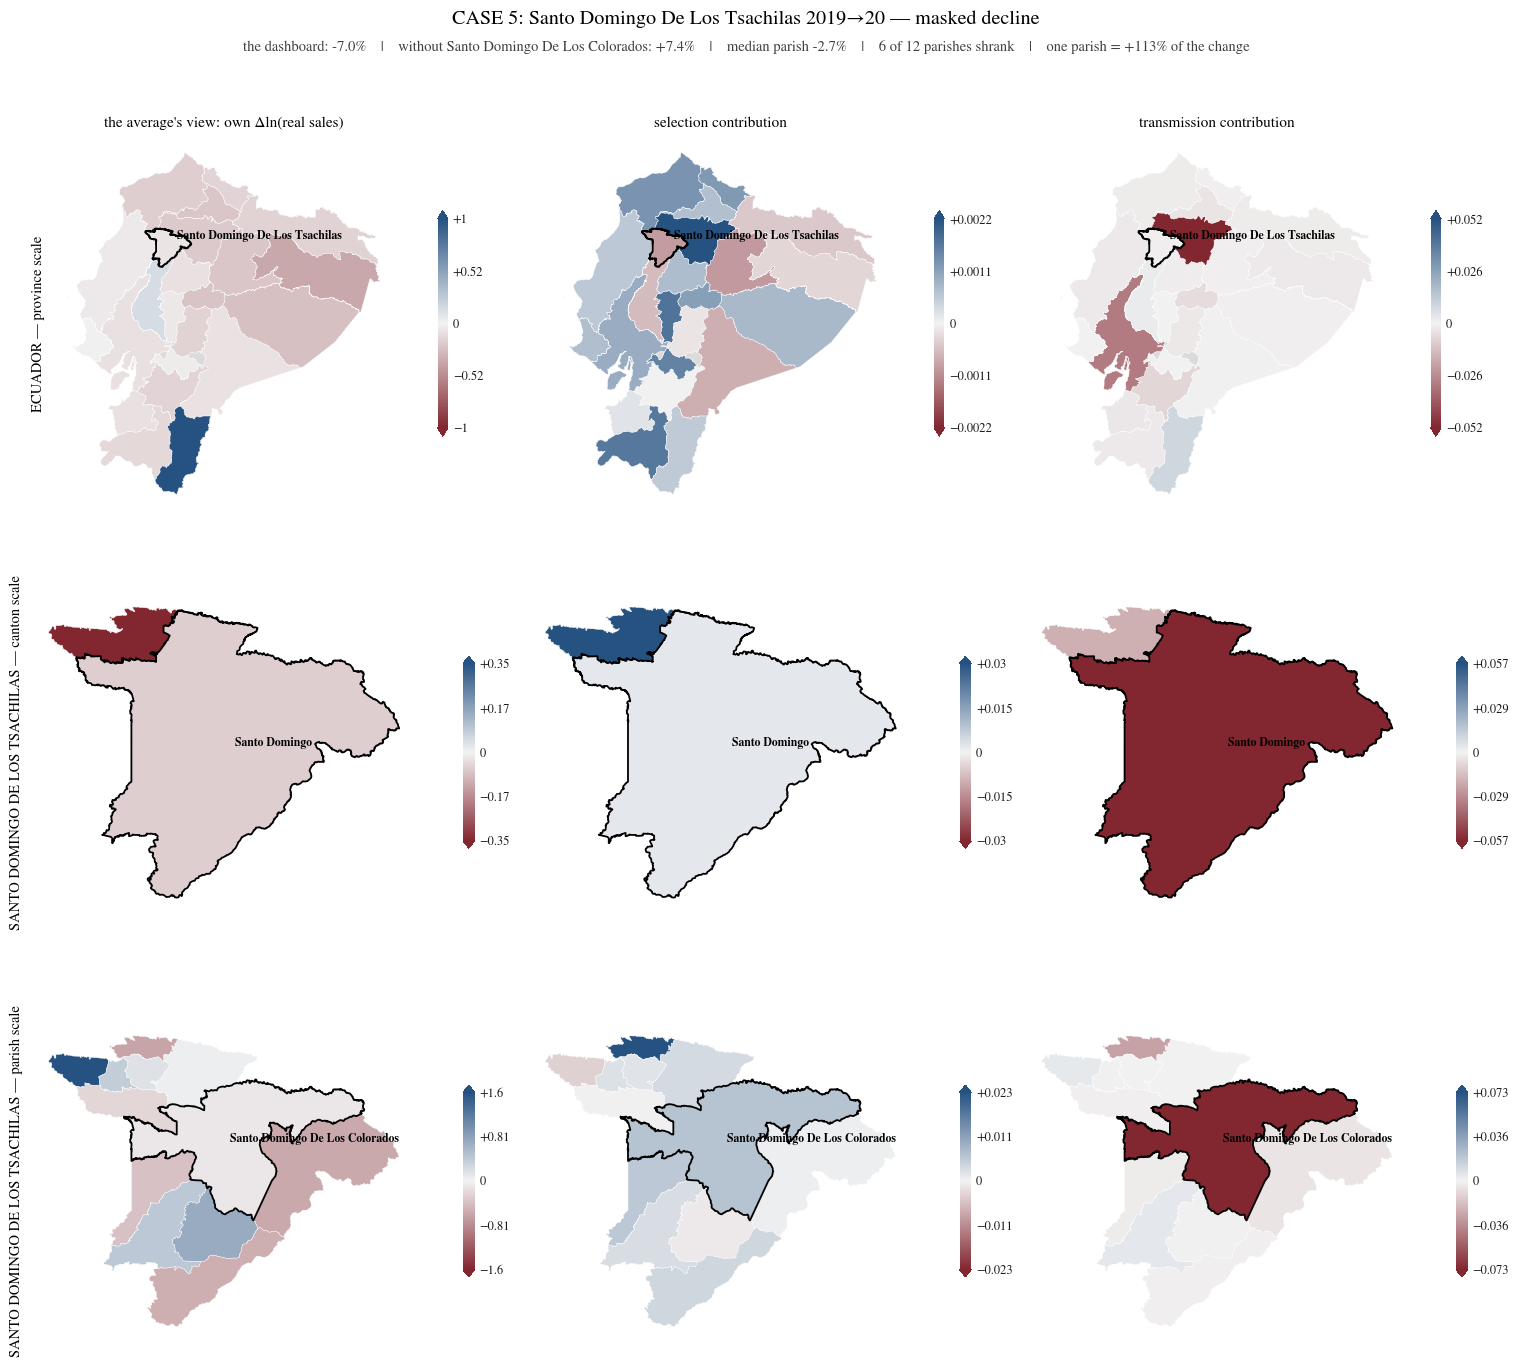

   within-Santo Domingo De Los Tsachilas Price (2019→20):  Δz̄ -0.0611  =  S +0.0509  +  T -0.1119    |    Santo Domingo De Los Colorados: sel_c +0.0067, trans_c -0.0849, own growth -0.09 log pts



saved -> results/story/masked_multiscale/case6_04_2017_2018.png


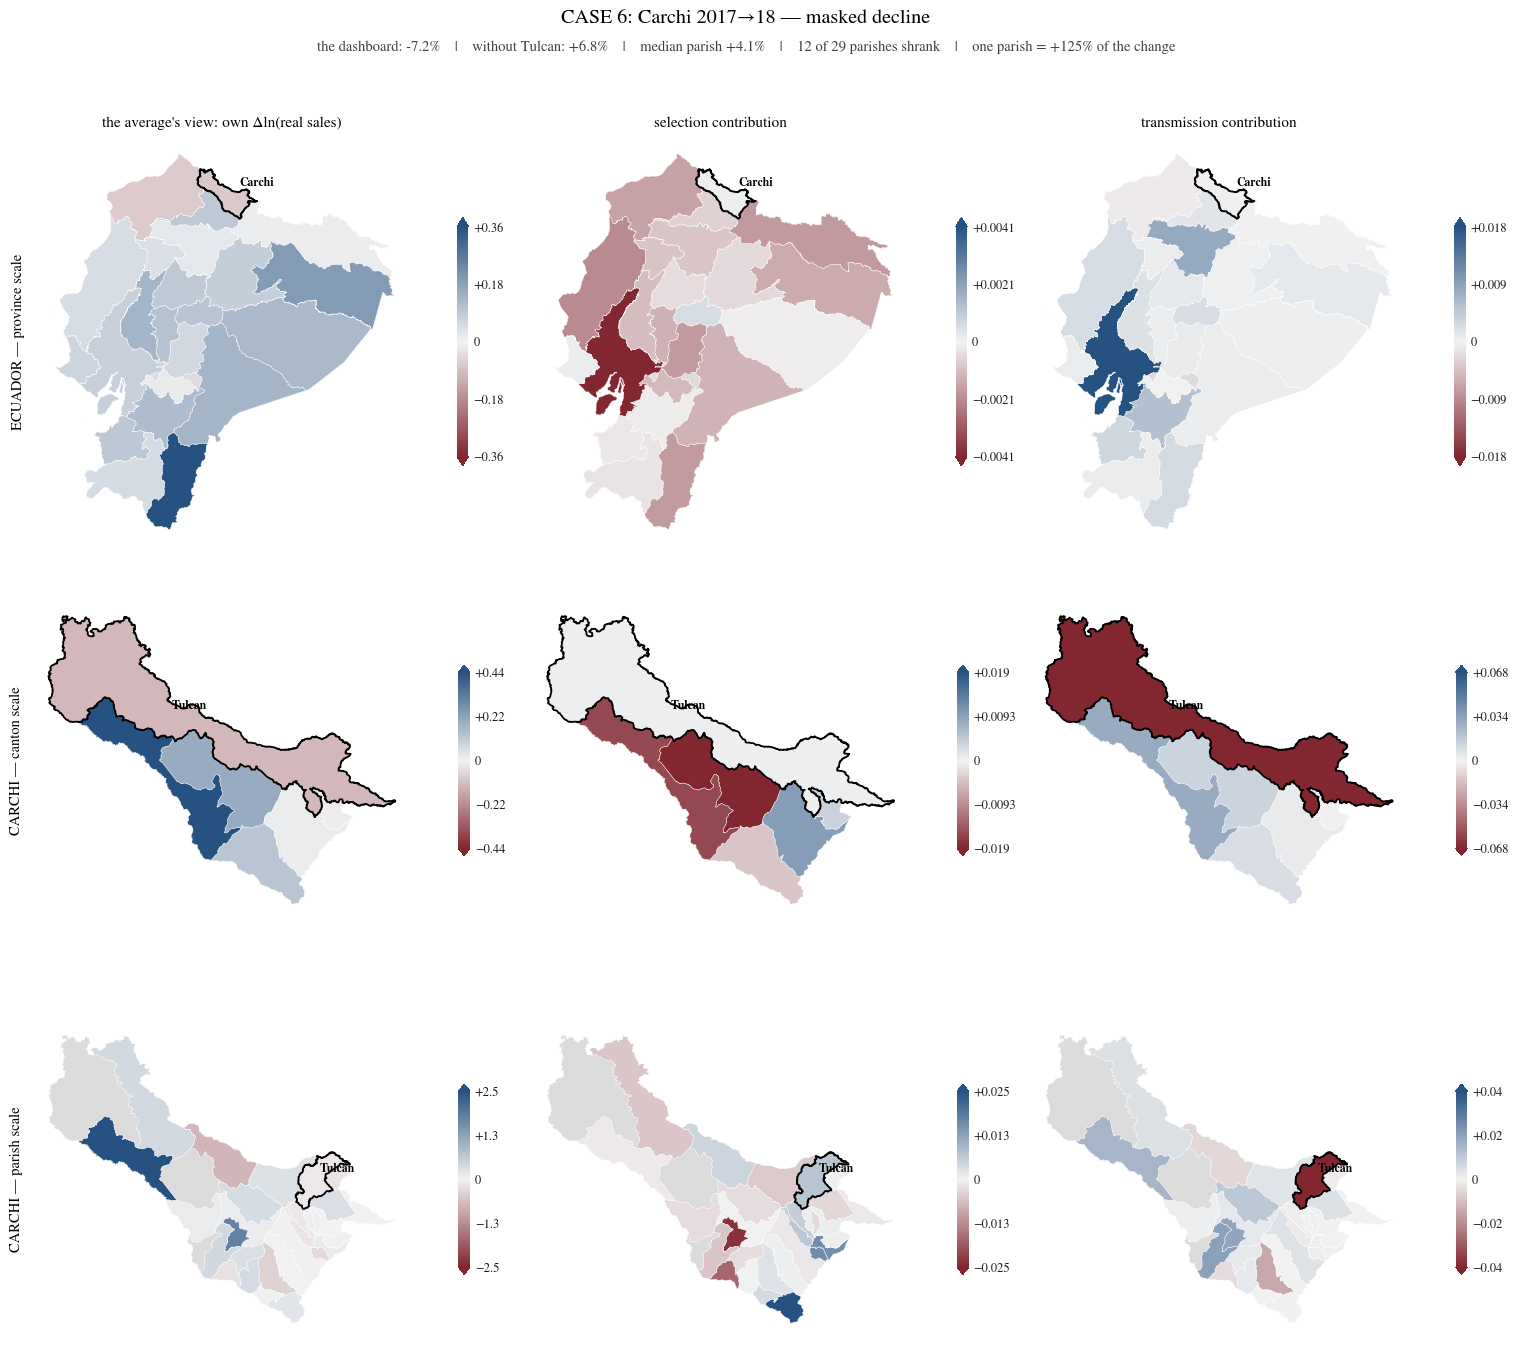

   within-Carchi Price (2017→18):  Δz̄ +0.0127  =  S +0.0163  +  T -0.0036    |    Tulcan: sel_c +0.0072, trans_c -0.0650, own growth -0.13 log pts



saved -> results/story/masked_multiscale/case7_02_2017_2018.png


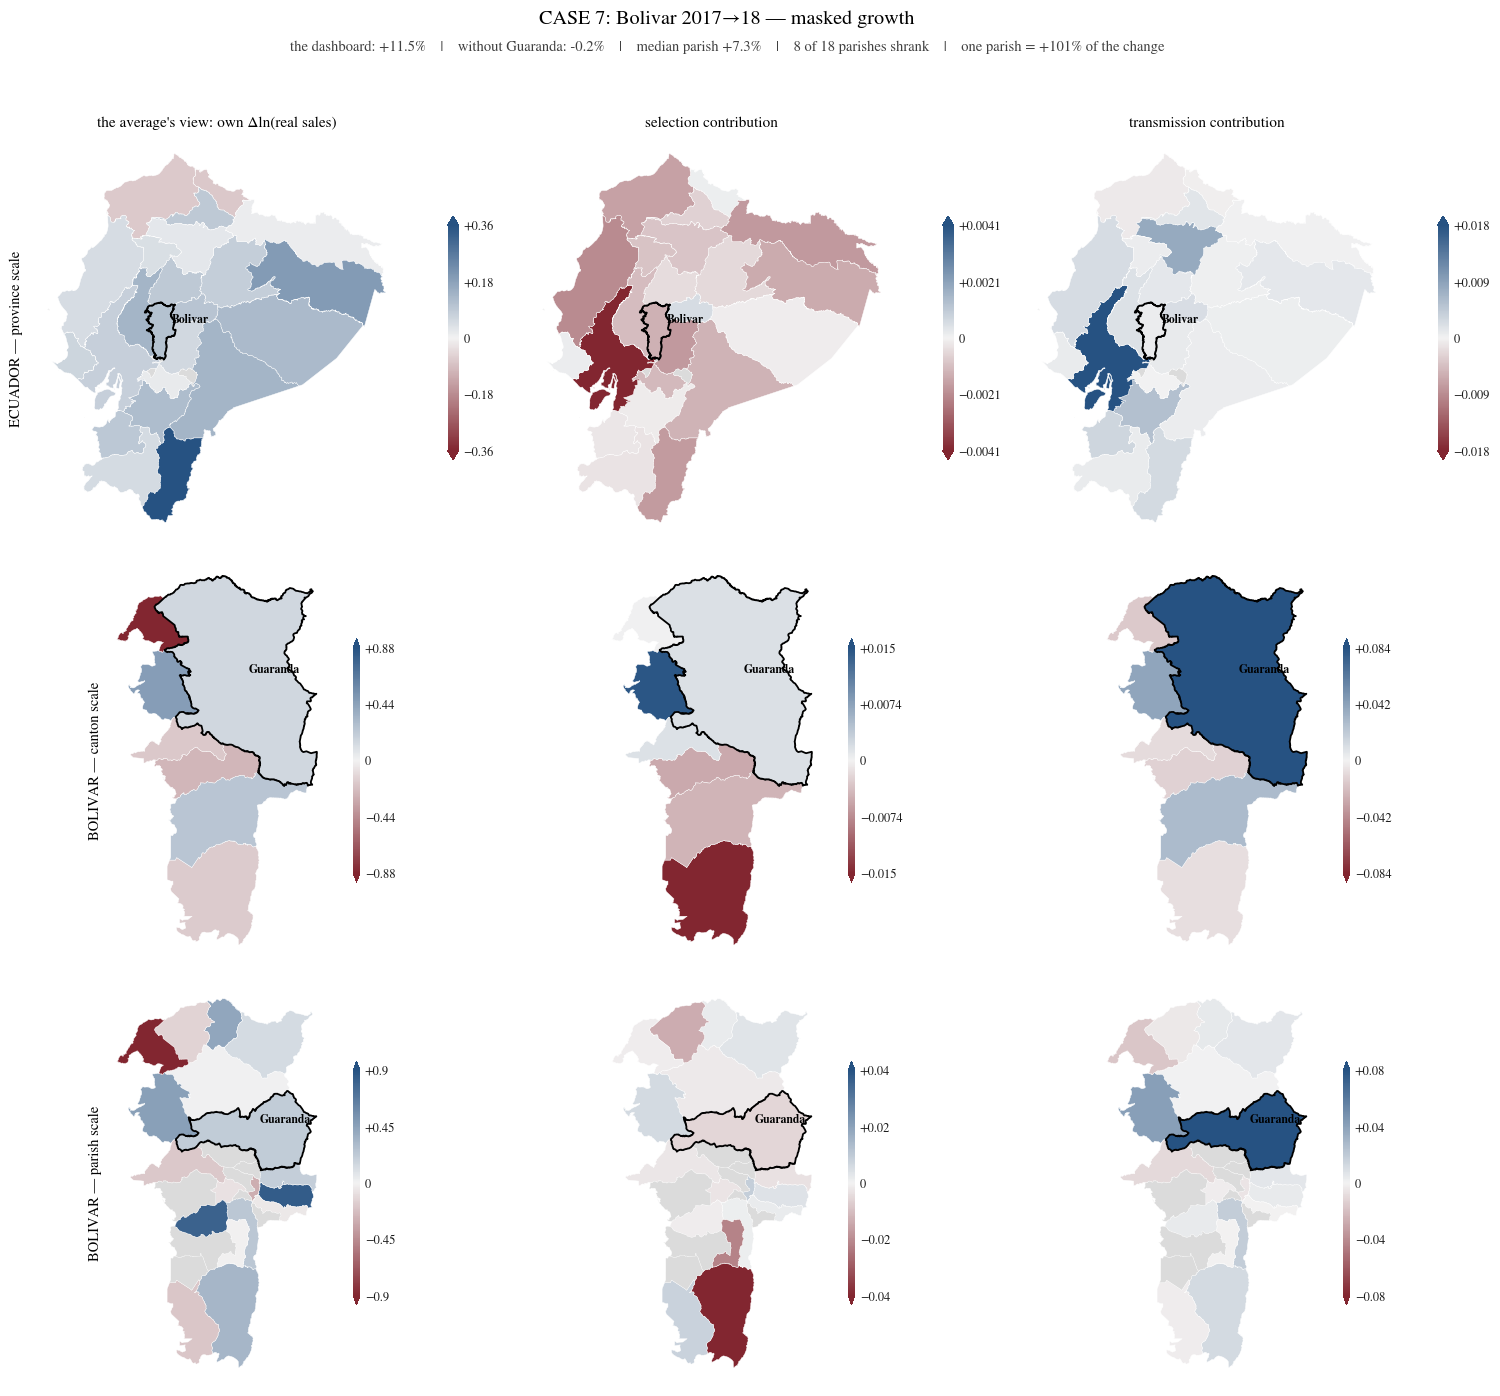

   within-Bolivar Price (2017→18):  Δz̄ +0.0897  =  S -0.0661  +  T +0.1558    |    Guaranda: sel_c -0.0053, trans_c +0.0998, own growth +0.22 log pts



saved -> results/story/masked_multiscale/case8_05_2019_2020.png


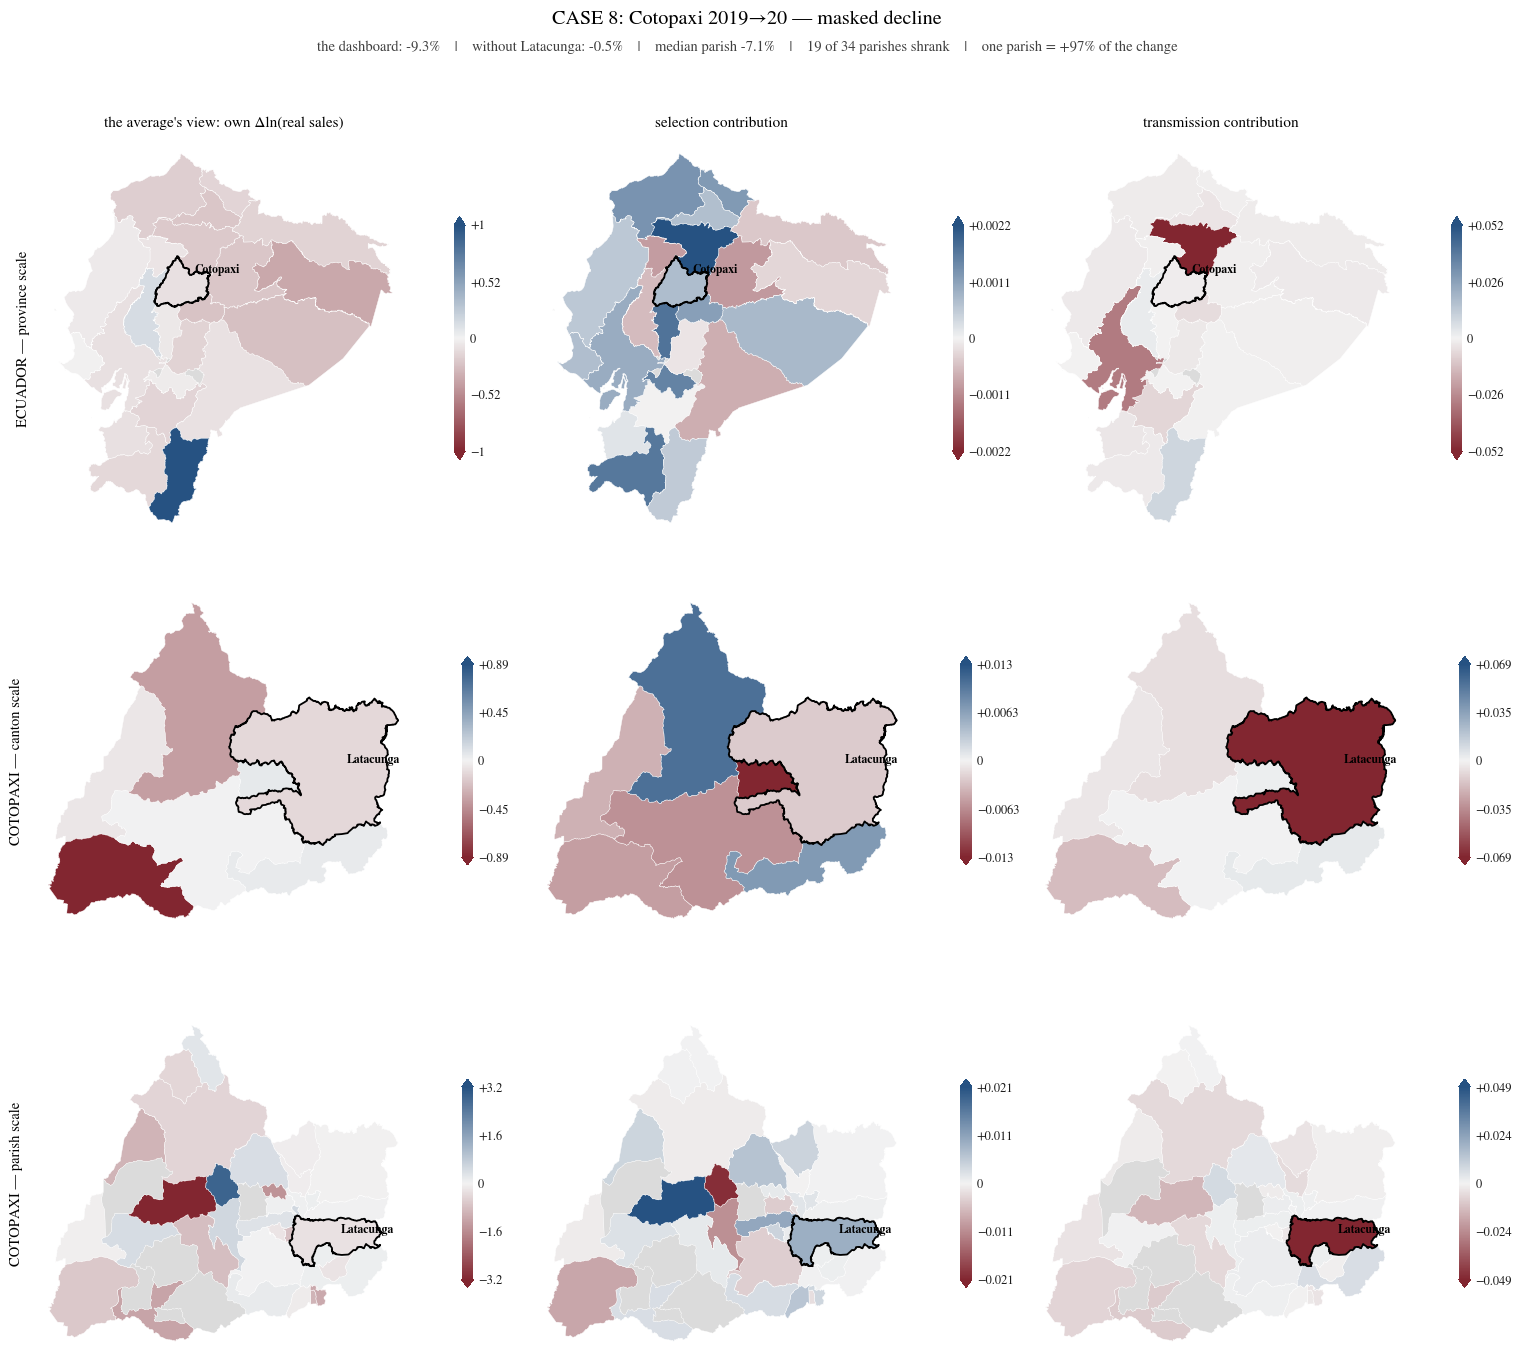

   within-Cotopaxi Price (2019→20):  Δz̄ -0.1218  =  S +0.0353  +  T -0.1571    |    Latacunga: sel_c +0.0090, trans_c -0.1152, own growth -0.25 log pts



saved -> results/story/masked_multiscale/case9_08_2017_2018.png


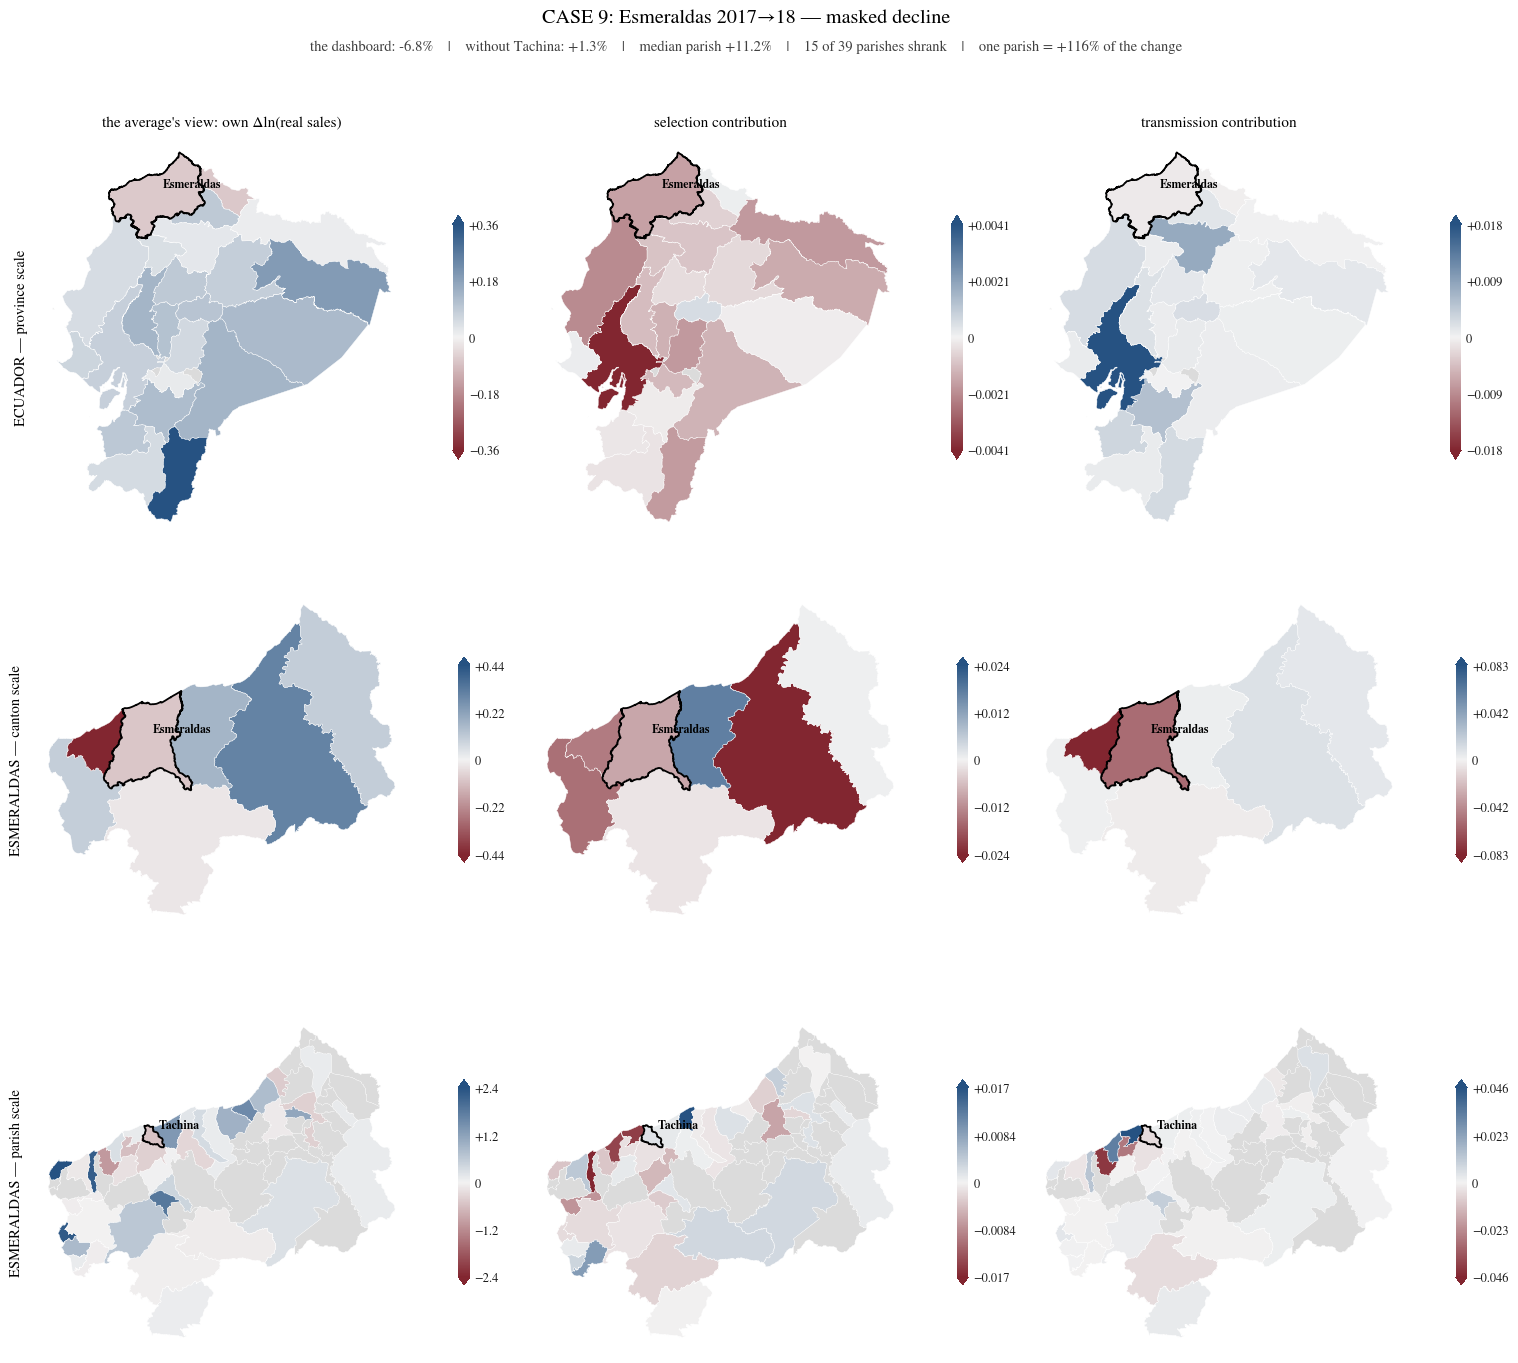

   within-Esmeraldas Price (2017→18):  Δz̄ +0.0121  =  S -0.0393  +  T +0.0513    |    Tachina: sel_c +0.0016, trans_c -0.0052, own growth -0.55 log pts



saved -> results/story/masked_multiscale/case10_06_2022_2023.png


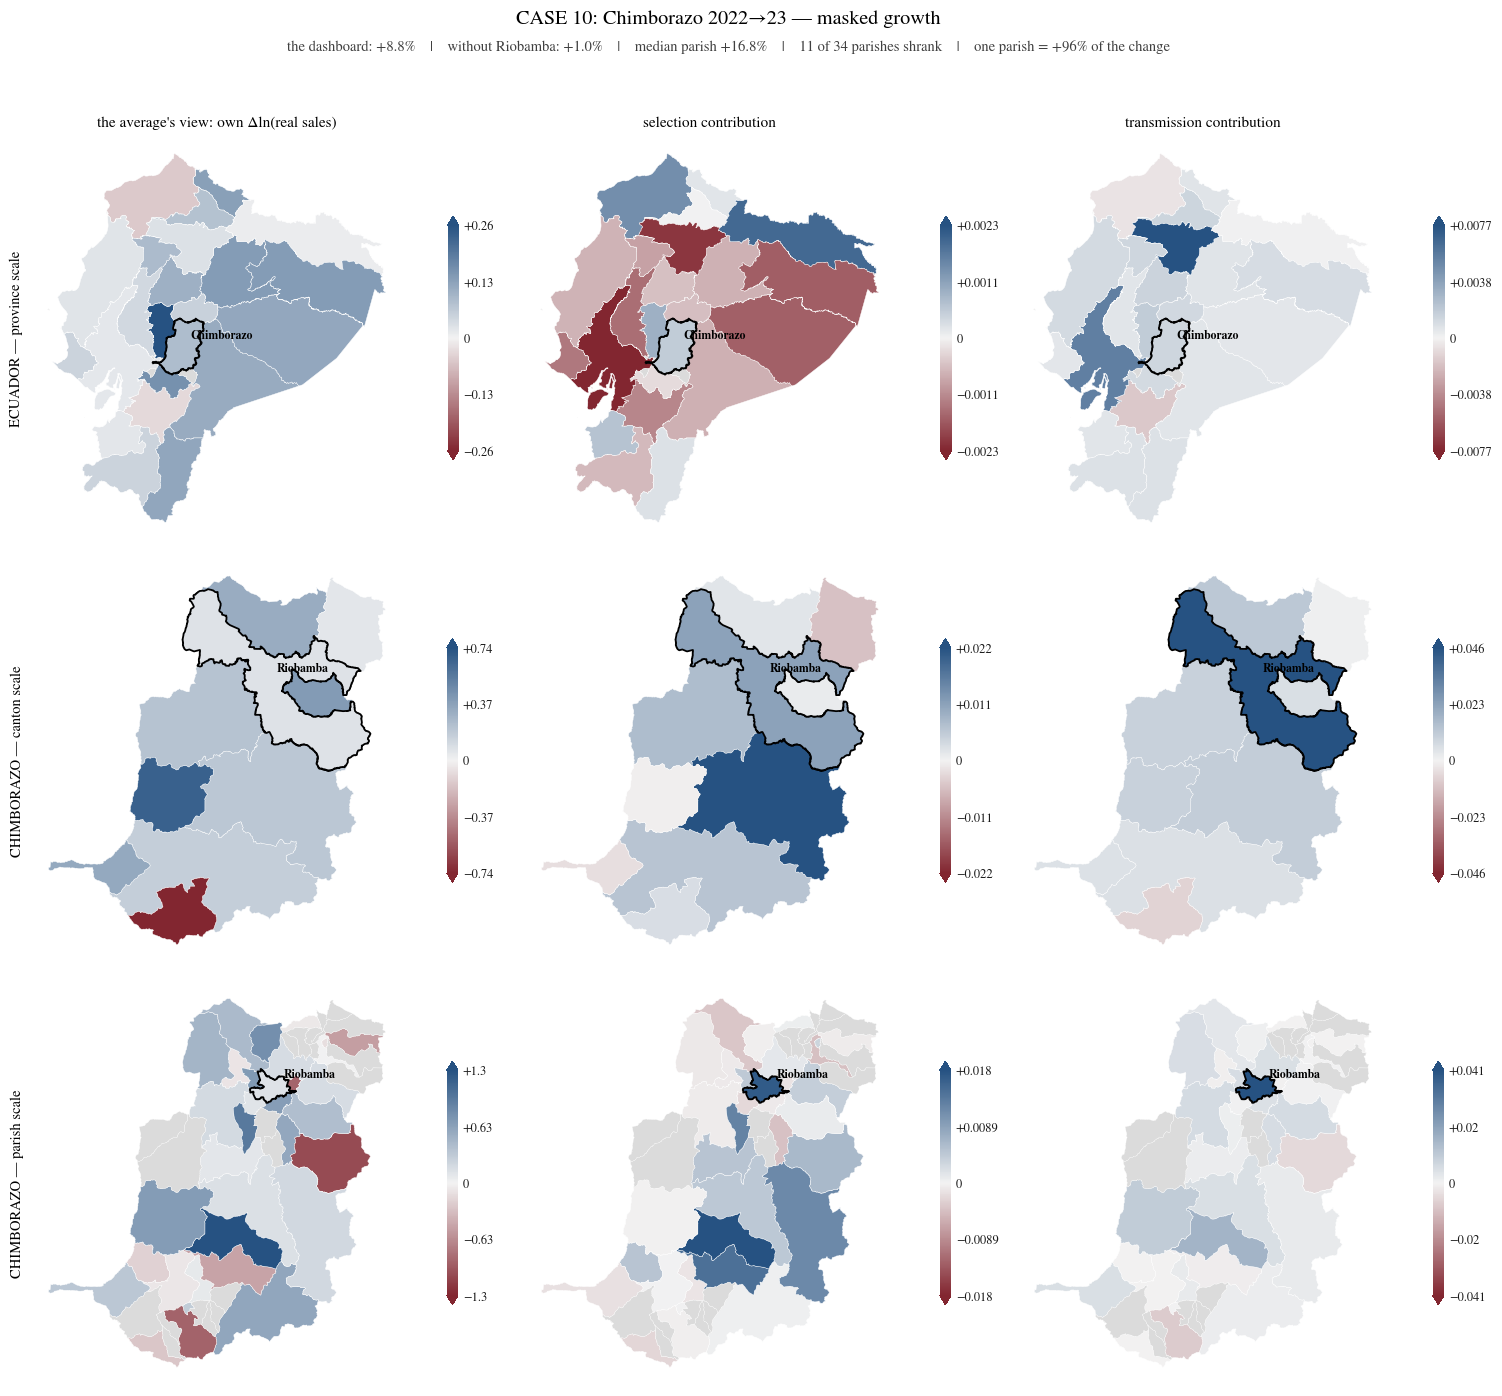

   within-Chimborazo Price (2022→23):  Δz̄ +0.2439  =  S +0.0854  +  T +0.1585    |    Riobamba: sel_c +0.0168, trans_c +0.0893, own growth +0.13 log pts



In [6]:
# ==============================================================================
# STEP E -- one 3x3 map panel per case: rows coarse -> fine, cols average -> S, T
# ==============================================================================
def choropleth(ax, geo, key, vals, col, outline_codes=(), label_code=None):
    'one map: geometry-left merge, symmetric diverging scale, grey = no data'
    m = geo.merge(vals[[col]], left_on=key, right_index=True, how="left")
    v = float(np.nanquantile(m[col].abs(), Q_CAP)) if m[col].notna().any() else np.nan
    if not np.isfinite(v) or v == 0:
        v = 1e-6
    m.plot(column=col, cmap=style.DIVERGING, norm=style.map_norm(v), ax=ax,
           edgecolor=style.EDGE, linewidth=0.3,
           missing_kwds=dict(color=style.NO_DATA, edgecolor=style.EDGE, linewidth=0.2))
    style.add_map_colorbar(ax, v)                  # the project's colour bar: blue = rise, red = fall
    for oc in outline_codes:                       # black outline on the culprit
        sel = m[m[key] == oc]
        if len(sel):
            sel.boundary.plot(ax=ax, color="black", linewidth=1.3)
            if oc == label_code:
                pt = sel.geometry.representative_point().iloc[0]
                nm = PNAME.get(oc, CNAME.get(oc, PROV.get(oc, oc))).split(" (")[0]
                ax.annotate(nm, (pt.x, pt.y), textcoords="offset points",
                            xytext=(6, 6), fontsize=8.5, fontweight="bold")
    ax.set_axis_off()


COLS = [("growth",  "the average's view: own Δln(real sales)"),
        ("sel_c",   "selection contribution"),
        ("trans_c", "transmission contribution")]


def case_panel(r, idx):
    'the 3x3 figure for one flagged (province, step) case'
    prov, y0, y1 = r["prov_code"], r["y0"], r["y1"]
    top_parish, top_canton = r["top_code"], r["top_code"][:4]
    tables = {"province": unit_price_table(y0, y1, 2),
              "canton":   unit_price_table(y0, y1, 4, within=prov),
              "parish":   unit_price_table(y0, y1, 6, within=prov)}
    rows = [("province", GEO["province"], "DPA_PROVIN", [prov], prov,
             "ECUADOR — province scale"),
            ("canton", GEO["canton"][GEO["canton"]["DPA_CANTON"].str.startswith(prov)],
             "DPA_CANTON", [top_canton], top_canton,
             f"{r['prov'].upper()} — canton scale"),
            ("parish", GEO["parish"][GEO["parish"]["DPA_PARROQ"].str.startswith(prov)],
             "DPA_PARROQ", [top_parish], top_parish,
             f"{r['prov'].upper()} — parish scale")]

    fig, axes = plt.subplots(3, 3, figsize=(15.5, 14.0))
    for ri, (level, geo, key, outline, label, rowtitle) in enumerate(rows):
        if geo.empty:                              # e.g. Galápagos: no polygons
            for ci in range(3):
                axes[ri, ci].text(0.5, 0.5, f"{r['prov']}: not in the shapefile",
                                  ha="center", va="center", fontsize=10, color="0.4")
                axes[ri, ci].set_axis_off()
            continue
        for ci, (col, collab) in enumerate(COLS):
            choropleth(axes[ri, ci], geo, key, tables[level], col, outline, label)
            if ri == 0:
                axes[ri, ci].set_title(collab, fontsize=11)
        axes[ri, 0].text(-0.02, 0.5, rowtitle, transform=axes[ri, 0].transAxes,
                         rotation=90, va="center", ha="right", fontsize=10.5)

    strip = (f"the dashboard: {np.expm1(r.G_agg) * 100:+.1f}%    |    without "
             f"{r['top'].split(' (')[0]}: {np.expm1(r.G_wo) * 100:+.1f}%    |    "
             f"median parish {np.expm1(r.med) * 100:+.1f}%    |    "
             f"{r.n_shrink} of {r.n} parishes shrank    |    "
             f"one parish = {r.top_dshare:+.0%} of the change")
    fig.suptitle(f"CASE {idx}: {r['prov']} {r['step']} — {r['kind']}",
                 fontsize=14.5, y=0.995)
    fig.text(0.5, 0.966, strip, ha="center", fontsize=10.5, color="0.25")
    fig.tight_layout(rect=(0.015, 0, 1, 0.955))
    out = OUT_DIR / f"case{idx}_{prov}_{y0}_{y1}"
    fig.savefig(f"{out}.png", dpi=200, bbox_inches="tight")
    fig.savefig(f"{out}.pdf", bbox_inches="tight")
    print(f"saved -> {out}.png")
    plt.show()


for i, r in CASES.iterrows():
    case_panel(r, i + 1)
    t = unit_price_table(r.y0, r.y1, 6, within=r.prov_code)
    tn = r["top"].split(" (")[0]
    print(f"   within-{r['prov']} Price ({r['step']}):  "
          f"Δz̄ {t.sel_c.sum() + t.trans_c.sum():+.4f}  =  "
          f"S {t.sel_c.sum():+.4f}  +  T {t.trans_c.sum():+.4f}    |    {tn}: "
          f"sel_c {t.sel_c.get(r.top_code, np.nan):+.4f}, "
          f"trans_c {t.trans_c.get(r.top_code, np.nan):+.4f}, "
          f"own growth {t.growth.get(r.top_code, np.nan):+.2f} log pts\n")

## Reading the five cases

**Case 1 — Bolívar 2023→24, masked growth.** The dashboard says +38.7 %; without Guaranda
it is −6.5 %, and 11 of 23 parishes shrank. The within-province decomposition is almost
pure transmission (S −0.019, T +0.224), and Guaranda alone contributes `trans_c` +0.29 —
its own sales jumped +0.59 log points (≈ +80 %) in a single year. One provincial capital
*is* the provincial boom; the countryside was flat to down. The parish-scale map turns
"Bolívar is booming" into "go find out what happened in Guaranda in 2024".

**Case 2 — Santo Domingo de los Tsáchilas 2020→21, masked growth.** +25.4 % vs −6.7 %
without the capital. This province is nearly one parish: Santo Domingo de los Colorados
holds ~9 of every 10 sales dollars, so the "province average" is simply the capital's
post-COVID base-effect rebound (`trans_c` +0.24 of T +0.26). Note the subtlety in the
strip: the *median* parish grew +12.3 % while the dollar-weighted rest fell −6.7 % — the
small satellites were recovering, the mid-sized ones were not. Three numbers, three
different economies; the average reported only one of them.

**Case 3 — Zamora Chinchipe 2018→19, masked growth (the enclave).** Fruta del Norte's
first production year: Los Encuentros' own sales rose +1.31 log points (×3.7) on a
handful of formal firms, +136 % of the province's dollar change. In the Price ledger the
same parish is almost invisible — `trans_c` +0.07 of T +0.29 — because a ~5-firm parish
carries almost no firm weight, and province-wide selection is *negative* (−0.04): firm
formation was favouring the low-sales parishes. The average says "Zamora boomed"; the
decomposition says "one mine turned on, while the typical firm's parish saw ordinary
catch-up dynamics" — and row 3 draws a black ring around the mine.

**Case 4 — Carchi 2019→20, masked decline (the entrepôt).** Dashboard −14.2 %, yet
without Tulcán the province grew +3.3 %. The within-province decomposition even has the
firm-weighted mean trait *rising* (Δz̄ +0.05 = S +0.14 + T −0.09): transmission's one big
dragger is Tulcán (`trans_c` −0.13, own sales −0.25 log pts as the closed Colombian
border strangled border commerce), while selection is strongly positive. **Selection and
transmission disagreeing in sign is exactly the flag**: dollars collapsed in one trade
hub while the rest of the province held or gained. Writing Carchi off as "collapsing
−14 %" would have misread 30 of its 31 parishes.

**Case 5 — Santo Domingo de los Tsáchilas 2019→20, masked decline.** The mirror image of
case 2, starring the same parish one year earlier: the capital's COVID hit (`trans_c`
−0.085, essentially all of T −0.11) is the entire provincial decline of −7.0 %, while the
dollar-weighted rest actually grew +7.4 %. Cases 5 and 2 together are the whipsaw lesson:
the same dominant parish dragged the average down in the shock year and then carried the
entire "+25 % boom" of the rebound — at no point in 2019–2021 did the provincial average
describe what a typical Santo Domingo parish was living through.

**Across all five:** the masking is always a *transmission* phenomenon at the parish
scale — one unit's own Δln(sales) — which is exactly why the coarse province-scale map
(row 1) can't show it and the zoom sequence can. Selection extremes, when they appear
(Carchi's +0.14), tell the complementary story of where firms were forming or dying. The
panels don't replace the case study; they tell you, from the data alone, *which* case
study to write.


## The recipe this notebook demonstrates

1. **Never trust a lone average.** A province's growth number is a dollar-weighted sum: one
   mine, one refinery ramp, one closed border town *is* the number, silently.
2. **Run the cheap diagnostics first.** Leave-one-out and the median cost nothing and flag
   every case above; the masking gap |G_agg − G_wo| ranks them.
3. **Decompose, then zoom.** The Price terms say *what kind* of story it is — transmission
   spikes = incumbents' own sales moved (a mine, a shock to an entrepôt); selection
   extremes = firms relocating/forming asymmetrically — and the within-province maps say
   *where*, down to the named parish.
4. **The average is fine again once you know what it hides.** After the culprit is
   identified you can report both ledgers honestly: "the province grew X%, of which
   almost everything is one parish; the median parish did Y%."

Figures and the full scan CSV are in `ecuador_firms_outputs/story/masked_multiscale/`.

## STEP F — the second way an average lies: four regimes cancelling to zero

Everything above catches the *loud* failure of an average: one parish **is** the number,
and leave-one-out exposes it. There is a quieter failure that leave-one-out cannot see.
Take a province where half the map grows while half declines: remove any single parish
and the aggregate barely moves; the median sits near zero; every dashboard test returns
"honest, boring average". Yet *nothing happened* is exactly wrong — several different
things happened, and they cancelled.

The Price terms already contain the antidote, if we read them **per parish, with their
signs**. Since `trans_c = q·(z₁ − z₀)` and `q > 0`, transmission carries the parish's own
growth sign — it separates growing places from declining ones. And
`sel_c = p·(w/W̄ − 1)·(z₀ − z̄₀)` is the axis a sales average simply does not have: whether
the **firm base** is shifting toward or away from the parish, weighted by where it
started. The sign pair sorts every parish into one of four regimes:

|  | **T+ — own sales up** | **T− — own sales down** |
|---|---|---|
| **S− — gaining firm share\*** | **expansion**: firms flow in and sales rise — the genuine boomtown | **dilution**: firms keep arriving while sales fall — more firms chasing fewer dollars |
| **S+ — losing firm share\*** | **consolidation**: sales rise on a flat or shrinking firm base — fewer, bigger winners | **abandonment**: firms leave and sales fall — the true decay |

\*The share-reading of S holds for every parish that starts *below* the firm-weighted
mean trait `z̄₀`. In a capital-dominated province that is everyone except the capital
itself, whose firms pull `z̄₀` up toward its own level; for a parish above the mean the
roles flip, and the code below calls out any such exception explicitly.

**The finder.** The most instructive case is the province-year where *everything happens
at once*: at least `MIN_QUAD` parishes in every quadrant, at least `MIN_UPDOWN` parishes
growing **and** declining, ranked by `balance` — the smallest quadrant's share of the
total ledger mass Σ(|sel_c| + |trans_c|), so 0.25 would mean four exactly-equal cells.

In [7]:
# ==============================================================================
# STEP F -- find the province-year that lives in all four quadrants at once
# ------------------------------------------------------------------------------
# STEP D's parish table plus the mechanism columns the quadrants need; the Price
# terms themselves come from unit_price_table, so the two views cannot drift.
# ==============================================================================
MIN_QUAD   = 3          # parishes required in every quadrant
MIN_UPDOWN = 4          # parishes required with growth > 0 AND with growth < 0
QUADS      = ["S-T+", "S+T+", "S-T-", "S+T-"]        # fixed display order


def parish_price_detail(y0, y1, within):
    '''unit_price_table at parish scale inside one province, extended with firm
    counts, dollar levels, rel_fit = w/W̄, z0_dev = z0 − z̄0, the regime (the
    sign pair of sel_c/trans_c) and the ledger mass |sel_c| + |trans_c|.'''
    t = unit_price_table(y0, y1, 6, within=within)
    d = panel[panel["year"].isin([y0, y1])]
    if 2024 in (y0, y1):
        d = d[d["m"].isin(MONTHS_2324)]
    d = d[d["cod_parr"].str.startswith(within)]
    sales = d.groupby(["cod_parr", "year"])["real_sales"].sum().unstack().loc[t.index]
    firms = (d.groupby(["cod_parr", "year", "m"])["total_firms"].sum()
               .groupby(["cod_parr", "year"]).mean().unstack().loc[t.index])
    n0, n1 = firms[y0], firms[y1]
    p, w = n0 / n0.sum(), n1 / n0
    W, Z0 = (p * w).sum(), (p * np.log(sales[y0])).sum()
    assert np.allclose(p * (w / W - 1) * (np.log(sales[y0]) - Z0), t.sel_c)
    return t.assign(n0=n0, n1=n1, s0=sales[y0], s1=sales[y1], q=n1 / n1.sum(),
                    rel_fit=w / W, z0_dev=np.log(sales[y0]) - Z0,
                    quad=np.where(t.trans_c >= 0,
                                  np.where(t.sel_c >= 0, "S+T+", "S-T+"),
                                  np.where(t.sel_c >= 0, "S+T-", "S-T-")),
                    mass=t.sel_c.abs() + t.trans_c.abs())


provs_in_panel = set(panel["cod_parr"].str[:2].unique())
qrows = []
for y0, y1 in STEPS:
    for pc in sorted(set(GEO["province"]["DPA_PROVIN"]) & provs_in_panel):
        if pc not in PROV:
            continue
        t = parish_price_detail(y0, y1, pc)
        if len(t) < 4 * MIN_QUAD:
            continue
        counts = t["quad"].value_counts().reindex(QUADS, fill_value=0)
        mass = t.groupby("quad")["mass"].sum().reindex(QUADS, fill_value=0.0)
        qrows.append(dict(prov_code=pc, prov=PROV[pc], y0=y0, y1=y1,
                          step=f"{y0}→{str(y1)[2:]}", n=len(t),
                          **{f"n_{qd}": int(c) for qd, c in counts.items()},
                          min_quad=int(counts.min()),
                          balance=mass.min() / mass.sum(),
                          n_grow=int((t.growth > 0).sum()),
                          n_decl=int((t.growth < 0).sum())))
qscan = (pd.DataFrame(qrows)
         .merge(scan[["prov_code", "y0", "G_agg", "G_wo", "med"]],
                on=["prov_code", "y0"], how="left"))
qscan.to_csv(OUT_DIR / "four_quadrant_scan.csv", index=False)

cand = qscan[(qscan.min_quad >= MIN_QUAD) & (qscan.n_grow >= MIN_UPDOWN) &
             (qscan.n_decl >= MIN_UPDOWN)].sort_values("balance", ascending=False)
print(f"{len(cand)} of {len(qscan)} province-years hold ≥{MIN_QUAD} parishes in every "
      f"quadrant (balance: 0.25 = the four cells carry equal shares of the ledger "
      f"mass Σ|sel_c|+|trans_c|)\n")
show_q = cand.head(5).assign(G_agg=pct(cand.head(5).G_agg), G_wo=pct(cand.head(5).G_wo),
                             balance=cand.head(5).balance.round(3))
print(show_q[["prov", "step", "n", "G_agg", "G_wo", "n_S-T+", "n_S+T+", "n_S-T-",
              "n_S+T-", "balance", "n_grow", "n_decl"]].to_string(index=False))

CASE_F = cand.iloc[0]
in_stepB = ((flagged.prov_code == CASE_F.prov_code) & (flagged.y0 == CASE_F.y0)).any()
print(f"\nthe featured case: {CASE_F.prov} {CASE_F.step} — the dashboard says "
      f"{np.expm1(CASE_F.G_agg) * 100:+.1f}%, leave-one-out {np.expm1(CASE_F.G_wo) * 100:+.1f}%, "
      f"median parish {np.expm1(CASE_F.med) * 100:+.1f}% — "
      f"{'flagged' if in_stepB else 'NOT flagged'} by the STEP-B detector, yet "
      f"{CASE_F.n_grow} of {CASE_F.n} parishes grew, {CASE_F.n_decl} declined, and every "
      f"quadrant is busy ({CASE_F['n_S-T+']}/{CASE_F['n_S+T+']}/{CASE_F['n_S-T-']}/"
      f"{CASE_F['n_S+T-']} parishes in S−T+/S+T+/S−T−/S+T−).")

104 of 154 province-years hold ≥3 parishes in every quadrant (balance: 0.25 = the four cells carry equal shares of the ledger mass Σ|sel_c|+|trans_c|)

      prov    step  n  G_agg  G_wo  n_S-T+  n_S+T+  n_S-T-  n_S+T-  balance  n_grow  n_decl
      Loja 2023→24 67    0.0   1.2      19      15      15      18    0.199      34      33
 Sucumbios 2023→24 30    5.2   5.3       8       6       9       7    0.192      14      16
  Los Rios 2018→19 27    0.7  -0.0       6       8       5       8    0.189      14      13
     Azuay 2018→19 69    0.2  -0.8      23      17      15      14    0.188      40      29
Chimborazo 2023→24 35   -1.0   3.4      10       9       8       8    0.163      19      16

the featured case: Loja 2023→24 — the dashboard says +0.0%, leave-one-out +1.2%, median parish +0.2% — NOT flagged by the STEP-B detector, yet 34 of 67 parishes grew, 33 declined, and every quadrant is busy (19/15/15/18 parishes in S−T+/S+T+/S−T−/S+T−).


## FIG F — one province, three lenses

- **Left — the average's ingredient.** Every parish's own Δln(real sales), on the same
  diverging scale as the STEP-E maps. Blue beside red everywhere: a place growing next to
  a place declining is this province's *normal condition* — and summed with dollar
  weights it nets out to almost exactly zero.
- **Middle — the triage map.** The same parishes, now colored by regime. Color here means
  a *kind* of story, not an amount: each hue is a different follow-up question. Which
  question to ask *first* is what the right panel ranks.
- **Right — the ledger itself.** Each parish plotted by its two contributions; dot area is
  its share of the province's firms. Distance from the horizontal axis = how much the
  parish's own growth moves the provincial mean trait; distance from the vertical axis =
  how much firm reallocation does. The capital sits far left: the single largest entry in
  the whole ledger, contributed by a parish whose own growth was +0.2 % — the average's
  blindest spot is the decomposition's loudest signal.

saved -> results/story/masked_multiscale/figF_four_quadrants_11_2023_2024.png


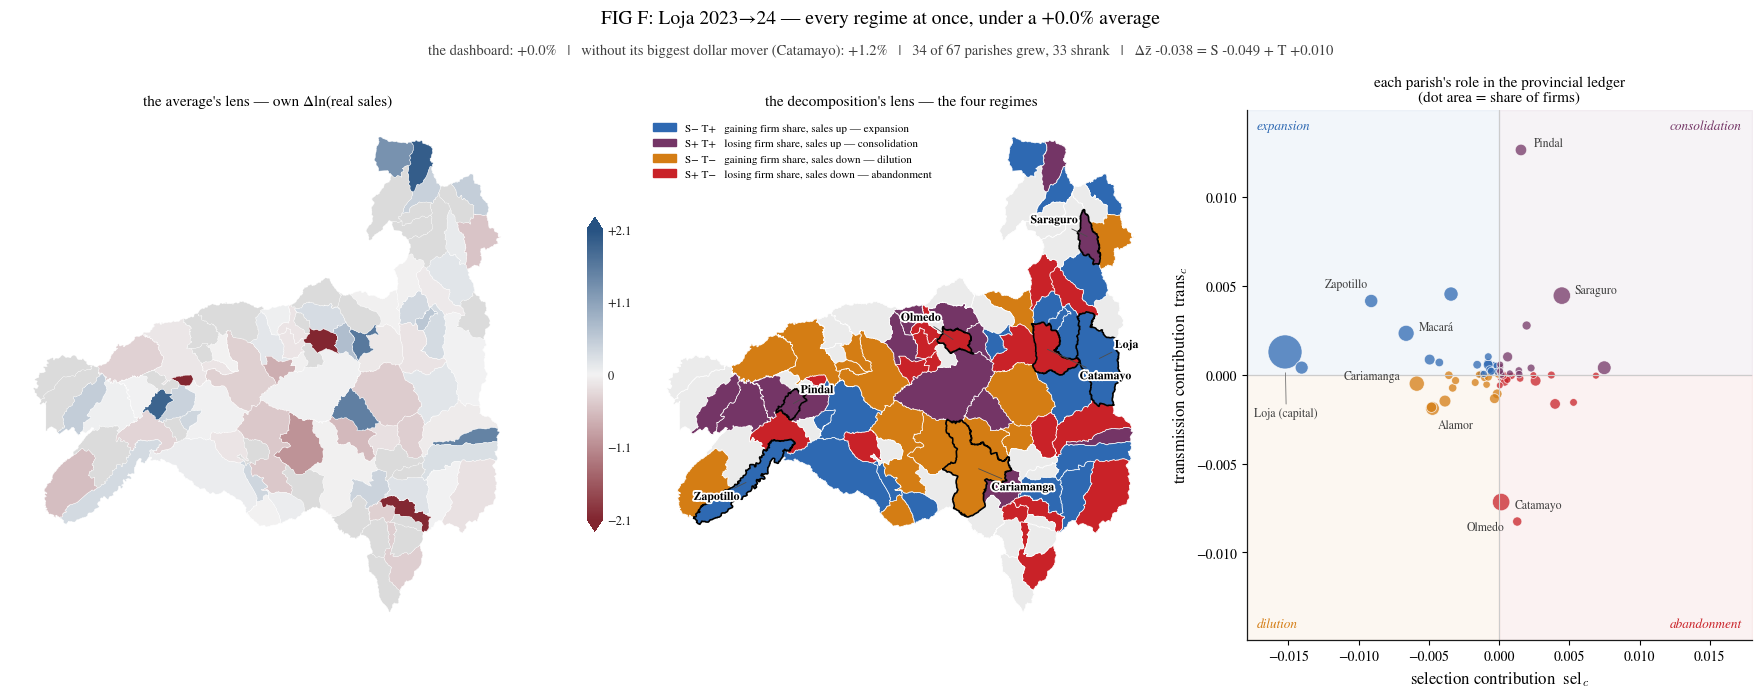


the four-quadrant ledger of Loja 2023→24 (67 parishes, $1,006M -> $1,007M):
  S-T+ expansion     19 parishes   S -0.0664  T +0.0187   e.g. Loja (+0% sales, 2486→2515 firms);  Celica (+3% sales, 30→41 firms)
  S+T+ consolidation 15 parishes   S +0.0225  T +0.0232   e.g. Pindal (+570% sales, 24→24 firms);  Saraguro (+11% sales, 155→154 firms)
  S-T- dilution      15 parishes   S -0.0356  T -0.0107   e.g. Urdaneta (-38% sales, 10→14 firms);  Alamor (-12% sales, 47→54 firms)
  S+T- abandonment   18 parishes   S +0.0310  T -0.0211   e.g. Olmedo (-98% sales, 8→8 firms);  Catamayo (-15% sales, 152→156 firms)

  * Loja (Loja) starts above the firm-weighted mean trait, so its S− reads the other way: firm growth 0.99× the provincial mean at a high base — deconcentration. Its sel_c -0.0152 is the largest single ledger entry in the province, from a parish whose own sales growth was +0.2%.

where to look first — the six biggest ledger entries:
  Loja (Loja)                              S-T+ expans

In [8]:
# ==============================================================================
# FIG F -- the featured case: growth map | regime map | the S-T plane
# ------------------------------------------------------------------------------
# Quadrant colors are a 4-hue categorical set that passes the CVD-safety
# validator on every pair (cool hues = growing places, warm = declining).
# ==============================================================================
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

QUAD_COLOR  = {"S-T+": style.BLUE, "S+T+": style.PURPLE, "S-T-": style.ORANGE, "S+T-": style.RED}
QUAD_NAME   = {"S-T+": "expansion", "S+T+": "consolidation",
               "S-T-": "dilution",  "S+T-": "abandonment"}
QUAD_LEGEND = {"S-T+": "S− T+   gaining firm share, sales up — expansion",
               "S+T+": "S+ T+   losing firm share, sales up — consolidation",
               "S-T-": "S− T−   gaining firm share, sales down — dilution",
               "S+T-": "S+ T−   losing firm share, sales down — abandonment"}
QUAD_DARK   = dict(QUAD_COLOR)        # labels take the colour of their quadrant
HALO = [pe.withStroke(linewidth=2.6, foreground="white")]

F = parish_price_detail(CASE_F.y0, CASE_F.y1, CASE_F.prov_code)
F["name"] = [PNAME.get(c, c) for c in F.index]
F.to_csv(OUT_DIR / "four_quadrant_case_detail.csv")
PARQ = GEO["parish"][GEO["parish"]["DPA_PARROQ"].str.startswith(CASE_F.prov_code)]

G_F, S_F, T_F = np.log(F.s1.sum() / F.s0.sum()), F.sel_c.sum(), F.trans_c.sum()
top_ = (F.s1 - F.s0).abs().idxmax()
G_wo_F = np.log(F.drop(top_).s1.sum() / F.drop(top_).s0.sum())

fig = plt.figure(figsize=(17.5, 6.9), layout="constrained")
fig.get_layout_engine().set(rect=(0, 0, 1, 0.90))
axA, axB, axC = fig.subplots(1, 3, width_ratios=[1.02, 1.02, 1.0])

# --- left: the average's ingredient, same grammar as every STEP-E map ---------
choropleth(axA, PARQ, "DPA_PARROQ", F, "growth")
axA.set_title("the average's lens — own Δln(real sales)", fontsize=11)

# --- middle: the regime map; hand-picked exemplars outlined and labelled ------
mq = PARQ.merge(F[["quad"]], left_on="DPA_PARROQ", right_index=True, how="left")
mq.plot(color=mq["quad"].map(QUAD_COLOR).fillna("0.92"), ax=axB,
        edgecolor="white", linewidth=0.5)
MAP_ANN = {"110150": ("Loja", 12, 8, "left"),       # hand-staggered, like OFFS in FIG 0
           "111450": ("Pindal", 6, 8, "left"),
           "111150": ("Saraguro", -8, 10, "right"),
           "111350": ("Zapotillo", -6, -13, "right"),
           "110350": ("Catamayo", 24, -22, "left"),
           "111650": ("Olmedo", -10, 14, "right"),
           "110250": ("Cariamanga", 10, -16, "left")}
for code, (nm, dx, dy, ha) in MAP_ANN.items():
    hit = mq[mq["DPA_PARROQ"] == code]
    if len(hit) and code in F.index:
        hit.boundary.plot(ax=axB, color="black", linewidth=1.2)
        ptx = hit.geometry.representative_point().iloc[0]
        axB.annotate(nm, (ptx.x, ptx.y), textcoords="offset points", xytext=(dx, dy),
                     ha=ha, fontsize=8.5, fontweight="bold", path_effects=HALO,
                     arrowprops=dict(arrowstyle="-", lw=0.6, color="0.3",
                                     shrinkA=0, shrinkB=1))
axB.legend(handles=[mpatches.Patch(color=c, label=QUAD_LEGEND[qd])
                    for qd, c in QUAD_COLOR.items()],
           loc="upper left", fontsize=8, frameon=False)
axB.set_title("the decomposition's lens — the four regimes", fontsize=11)
axB.set_axis_off()

# --- right: the plane; dot area = share of the province's firms ---------------
xl, yl = F.sel_c.abs().max() * 1.18, F.trans_c.abs().max() * 1.18
for qd, c in QUAD_COLOR.items():
    axC.fill_between((0, xl) if "S+" in qd else (-xl, 0),
                     *((0, yl) if "T+" in qd else (-yl, 0)), color=c, alpha=0.06)
axC.axhline(0, color="0.8", lw=0.8); axC.axvline(0, color="0.8", lw=0.8)
axC.scatter(F.sel_c, F.trans_c, s=12 + 700 * np.sqrt(F.q),
            c=F["quad"].map(QUAD_COLOR), alpha=0.75, edgecolor="white", lw=0.6)
PLANE_ANN = {"111450": ("Pindal", 9, 3), "111150": ("Saraguro", 9, 2),
             "111350": ("Zapotillo", -2, 10), "110850": ("Macará", 9, 2),
             "110350": ("Catamayo", 10, -4), "111650": ("Olmedo", -9, -6),
             "110250": ("Cariamanga", -12, 3), "111050": ("Alamor", 4, -14)}
for code, (nm, dx, dy) in PLANE_ANN.items():
    if code in F.index:
        axC.annotate(nm, (F.loc[code, "sel_c"], F.loc[code, "trans_c"]),
                     textcoords="offset points", xytext=(dx, dy),
                     ha="left" if dx > 0 else "right", fontsize=8.5, color="0.25")
if "110150" in F.index:                            # the capital's dot is huge: leader line
    axC.annotate("Loja (capital)", (F.loc["110150", "sel_c"], F.loc["110150", "trans_c"]),
                 textcoords="offset points", xytext=(-22, -46), ha="left",
                 fontsize=8.5, color="0.25",
                 arrowprops=dict(arrowstyle="-", lw=0.6, color="0.45",
                                 shrinkA=0, shrinkB=15))
for qd, (fx, fy) in {"S-T+": (-0.96, 0.94), "S+T+": (0.96, 0.94),
                     "S-T-": (-0.96, -0.94), "S+T-": (0.96, -0.94)}.items():
    axC.text(fx * xl, fy * yl, QUAD_NAME[qd], fontsize=9.5, style="italic",
             color=QUAD_DARK[qd], ha="left" if fx < 0 else "right", va="center")
axC.set_xlim(-xl, xl); axC.set_ylim(-yl, yl)
axC.set_xlabel("selection contribution  sel$_c$")
axC.set_ylabel("transmission contribution  trans$_c$")
axC.set_title("each parish's role in the provincial ledger\n(dot area = share of firms)",
              fontsize=11)
for s in ("top", "right"):
    axC.spines[s].set_visible(False)

fig.suptitle(f"FIG F: {CASE_F.prov} {CASE_F.step} — every regime at once, under a "
             f"{np.expm1(G_F) * 100:+.1f}% average", fontsize=14, y=0.99)
fig.text(0.5, 0.925, f"the dashboard: {np.expm1(G_F) * 100:+.1f}%   |   without its "
         f"biggest dollar mover ({F.loc[top_, 'name'].split(' (')[0]}): "
         f"{np.expm1(G_wo_F) * 100:+.1f}%   |   {int((F.growth > 0).sum())} of {len(F)} "
         f"parishes grew, {int((F.growth < 0).sum())} shrank   |   "
         f"Δz̄ {S_F + T_F:+.3f} = S {S_F:+.3f} + T {T_F:+.3f}",
         ha="center", fontsize=10.5, color="0.25")
out = OUT_DIR / f"figF_four_quadrants_{CASE_F.prov_code}_{CASE_F.y0}_{CASE_F.y1}"
fig.savefig(f"{out}.png", dpi=200, bbox_inches="tight")
fig.savefig(f"{out}.pdf", bbox_inches="tight")
print(f"saved -> {out}.png")
plt.show()

# --- the ledger, quadrant by quadrant, with named exemplars -------------------
print(f"\nthe four-quadrant ledger of {CASE_F.prov} {CASE_F.step} "
      f"({len(F)} parishes, ${F.s0.sum() / 1e6:,.0f}M -> ${F.s1.sum() / 1e6:,.0f}M):")
for qd in QUADS:
    sub = F[F["quad"] == qd].sort_values("mass", ascending=False)
    ex = ";  ".join(f"{r['name'].split(' (')[0]} ({np.expm1(r.growth) * 100:+.0f}% sales, "
                    f"{r.n0:.0f}→{r.n1:.0f} firms)" for _, r in sub.head(2).iterrows())
    print(f"  {qd} {QUAD_NAME[qd]:<13s} {len(sub):2d} parishes   S {sub.sel_c.sum():+.4f}  "
          f"T {sub.trans_c.sum():+.4f}   e.g. {ex}")

for code in F.index[F.z0_dev > 0]:                 # the share-reading exceptions
    r = F.loc[code]
    big = abs(r.sel_c) >= pd.concat([F.sel_c.abs(), F.trans_c.abs()]).max()
    print(f"\n  * {r['name']} starts above the firm-weighted mean trait, so its "
          f"S{'−' if r.sel_c < 0 else '+'} reads the other way: firm growth "
          f"{r.rel_fit:.2f}× the provincial mean at a high base — "
          f"{'de' if r.sel_c < 0 else ''}concentration"
          + (f". Its sel_c {r.sel_c:+.4f} is the largest single ledger entry in the "
             f"province, from a parish whose own sales growth was "
             f"{np.expm1(r.growth) * 100:+.1f}%." if big else "."))

print("\nwhere to look first — the six biggest ledger entries:")
for code, r in F.sort_values("mass", ascending=False).head(6).iterrows():
    lead = "selection" if abs(r.sel_c) > abs(r.trans_c) else "transmission"
    print(f"  {r['name']:<40s} {r['quad']} {QUAD_NAME[r['quad']]:<13s} "
          f"mass {r.mass:.4f} ({lead}-led)   sales {np.expm1(r.growth) * 100:+7.1f}%   "
          f"firms {r.n0:5.0f}→{r.n1:5.0f}")

busy = F[F.mass >= F.mass.quantile(0.6)]           # same average, opposite regime
for lab, sub in [("growing", busy[(busy.growth > 0.05) & (busy.growth < 1.5)]),
                 ("declining", busy[(busy.growth < -0.05) & (busy.growth > -1.5)])]:
    a_, b_ = sub[sub.sel_c >= 0], sub[sub.sel_c < 0]
    if a_.empty or b_.empty:
        continue
    dg = np.abs(a_.growth.values[:, None] - b_.growth.values[None, :])
    ai, bi = np.unravel_index(dg.argmin(), dg.shape)
    a, b = a_.iloc[ai], b_.iloc[bi]
    print(f"\n  same average, opposite regime ({lab}): "
          f"{a['name'].split(' (')[0]} {np.expm1(a.growth) * 100:+.1f}% with firms "
          f"{a.n0:.0f}→{a.n1:.0f} ({QUAD_NAME[a['quad']]})  vs  "
          f"{b['name'].split(' (')[0]} {np.expm1(b.growth) * 100:+.1f}% with firms "
          f"{b.n0:.0f}→{b.n1:.0f} ({QUAD_NAME[b['quad']]})")

## Reading Loja 2023→24 — what two extra numbers buy you

**The dashboard's verdict.** A one-billion-dollar provincial economy whose real sales
moved +0.0 % — a net change of about $0.1 M on $1,006 M. Leave-one-out agrees (+1.2 %
without Catamayo), the median parish agrees (+0.2 %), and STEP B's detector — correctly —
never flags it: in FIG 0 this province-year is the most boring dot on the chart, at the
origin, flush with the diagonal. Every macro lens returns the same verdict: *nothing
happened in Loja*.

**What actually happened.** 34 parishes grew, 33 declined, the firm stock rose
3,459 → 3,549, and the ledger splits into four busy quadrants:

- **Expansion (S−T+, 19 parishes).** The border-and-valley belt is genuinely booming:
  Zapotillo +38 % sales with firms 37→45, Macará +8 % with 93→106, Celica +3 % with
  30→41. Firm formation is chasing places whose sales are also rising — textbook catch-up
  growth, completely invisible inside a +0.0 % province.
- **Consolidation (S+T+, 15).** Pindal — the country's self-styled corn capital —
  multiplied its sales ×6.7 in one year *with the same 24 firms*; Saraguro grew +11 % on
  a flat firm base; Catacocha +3 % while shedding firms 59→53. Sales up on a flat or
  thinning firm base: windfalls and shakeouts, not broad-based expansion — a different
  fragility, and a different follow-up question, than Zapotillo's boom.
- **Dilution (S−T−, 15).** Cariamanga (−2 %, firms 75→85), Alamor (−12 %, 47→54),
  Gonzanamá (−18 %, 22→27), Urdaneta (−38 %, 10→14). Firms keep *entering* markets whose
  sales are falling — more firms chasing fewer dollars. Defensive formalisation?
  Necessity entrepreneurship? The average cannot even see the phenomenon; the quadrant
  names it and pins it to four specific towns.
- **Abandonment (S+T−, 18).** Catamayo — the province's second economy and its airport —
  lost −15 %, the biggest dollar move in Loja (−$11 M), while its firm base only kept
  pace (it sits almost exactly on the S = 0 line: a nearly pure transmission shock).
  Olmedo's formal sales essentially vanished (−98 %) with its 8 firms still registered —
  a flag worth chasing *even if* the answer turns out to be administrative (one taxpayer
  re-registering elsewhere) rather than economic. Yangana kept falling as its firms went
  4→1.
- **The capital.** Loja city holds 85 % of the province's sales and 72 % of its firms;
  its own year was flat (+0.2 %), so the average gives it no story at all. Yet its
  `sel_c` of −0.015 is the *largest single entry in the whole ledger*: the capital's firm
  count grew +1.2 % while the provincial mean grew +2.6 % — the firm base is quietly
  tilting away from the high-sales hub toward the periphery. (In the plane, Celica — the
  #2 ledger entry — hides behind the capital's giant dot.)

**Why this beats the average — three concrete payoffs.**

1. **It separates identical averages into different stories.** Saraguro +11 % and Macará
   +8 % are the same color on the left map but opposite halves of the plane: one grew by
   concentration, the other by attraction. Yangana −16 % and Gonzanamá −18 % are twins to
   the average — but firms 4→1 versus 22→27 are opposite local futures. Fieldwork would
   ask *different questions* in each of those four towns; the average would have sent one
   questionnaire.
2. **It re-ranks where to look.** The dollar lens ranks parishes by size — the capital
   and Catamayo, always. The ledger ranks by contribution to the *typical firm's*
   trajectory, and its shortlist is the capital's quiet deconcentration, Celica's firm
   rush, Pindal's one-year windfall, Zapotillo's boom, Olmedo's disappearance — three of
   which no size ranking would ever surface.
3. **It reads zero correctly.** `G_agg = +0.0 %` says "no news". `Δz̄ = −0.039 =
   S −0.049 + T +0.010` says: the environment of the typical firm deteriorated by ~4 % in
   trait terms, because the firm base is reallocating toward parishes whose sales are
   *not* keeping up (the dilution belt) and away from the one parish where sales are
   highest. A dollar-weighted average — *any* average — is structurally unable to say
   that sentence.

**The recipe gains a fifth line.** STEP B's rule was *never trust a lone average when it
is loud*; STEP F's is *never trust it when it is quiet either, until the quadrants are
checked*. Leave-one-out catches the average that is one parish; the quadrant scan catches
the average that is a stand-off. A dashboard number deserves belief only when both tests
come back clean — and when they don't, `sel_c` and `trans_c` do more than flag *that*
something is happening: they say **where**, **which kind**, and **how much of the
provincial story each place owns** — which is exactly the shortlist the next case study
should start from.